# Projeto LendingClub


Para este projeto, estaremos explorando dados disponíveis publicamente de [LendingClub.com](www.lendingclub.com). Lending Club conecta pessoas que precisam de dinheiro (mutuários) com pessoas que têm dinheiro (investidores). Felizmente, como investidor, você gostaria de investir em pessoas que mostraram um perfil de ter uma alta probabilidade de pagá-lo de volta. Vamos tentar criar um modelo que ajude a prever isso.

O clube de empréstimo teve um [ano muito interessante em 2016](https://en.wikipedia.org/wiki/Lending_Club#2016), então vamos verificar alguns de seus dados e ter em mente o contexto. Esses dados são de antes mesmo de serem públicos.

Utilizaremos os dados de empréstimos de 2007-2010 e tentaremos classificar e prever se o mutuário pagou o empréstimo na íntegra. Você pode baixar os dados de [aqui](https://www.lendingclub.com/info/download-data.action) ou apenas usar o csv já fornecido. Recomenda-se que você use o csv fornecido, uma vez que foi limpo dos valores de NA.

Aqui estão o que as colunas representam:
* credit.policy: 1 se o cliente atender aos critérios de subscrição de crédito da LendingClub.com e 0 caso contrário.
* purpose: O objetivo do empréstimo (possíveis valores "credit_card", "debt_consolidation", "educacional", "major_purchase", "small_business" e "all_other").
* int.rate: a taxa de juros do empréstimo (uma taxa de 11% seria armazenada como 0.11). Os mutuários julgados por LendingClub.com para serem mais arriscados recebem taxas de juros mais elevadas.
* installment: as parcelas mensais devidas pelo mutuário se o empréstimo for financiado.
* log.annual.inc: O log natural da renda anual auto-relatada do mutuário.
* dti: Ratio dívida / rendimento do tomador do empréstimo (montante da dívida dividido pela receita anual).
* fico: a pontuação de crédito FICO do mutuário.
* days.with.cr.line: O número de dias em que o mutuário teve uma linha de crédito.
* revol.bal: Saldo rotativo do mutuário (montante não pago no final do ciclo de cobrança do cartão de crédito).
* revol.util: taxa de utilização da linha rotativa do mutuário (o valor da linha de crédito usada em relação ao crédito total disponível).
* inq.last.6mths: número de consultas do mutuário por credores nos últimos 6 meses.
* delinq.2yrs: o número de vezes que o mutuário havia passado mais de 30 dias em um pagamento nos últimos 2 anos.
* pub.rec: O número de registros públicos depreciativos do mutuário (arquivamentos de falências, ônus fiscais ou julgamentos).
* not.fully.paid: empréstimo terminará inadimplente (1) ou será pago integralmente (0).

# Imports

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics as mt
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier



from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve
)


from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold

from scipy.stats import randint

# Helper Function

In [2]:
def avaliar_modelo(model, X_test, y_test, yhat, nome_modelo='Modelo'):
    
    # ==========================================
    # Probabilidades da classe positiva (1)
    # ==========================================
    
    y_prob = model.predict_proba(X_test)[:, 1]
    
    
    # ==========================================
    # Métricas
    # ==========================================
    
    accuracy = accuracy_score(y_test, yhat)
    
    precision = precision_score(
        y_test,
        yhat,
        zero_division=0
    )
    
    recall = recall_score(
        y_test,
        yhat,
        zero_division=0
    )
    
    f1 = f1_score(
        y_test,
        yhat,
        zero_division=0
    )
    
    roc_auc = roc_auc_score(
        y_test,
        y_prob
    )
    
    pr_auc = average_precision_score(
        y_test,
        y_prob
    )
    
    
    # ==========================================
    # Matriz de confusão
    # ==========================================
    
    cm = confusion_matrix(y_test, yhat)
    
    tn, fp, fn, tp = cm.ravel()
    
    specificity = tn / (tn + fp)
    
    
    # ==========================================
    # Tabela de métricas
    # ==========================================
    
    metricas = pd.DataFrame({
        'Métrica': [
            'Accuracy',
            'Precision',
            'Recall',
            'F1-Score',
            'Specificity',
            'ROC-AUC',
            'PR-AUC'
        ],
        
        'Valor': [
            accuracy,
            precision,
            recall,
            f1,
            specificity,
            roc_auc,
            pr_auc
        ]
    })
    
    metricas['Valor'] = metricas['Valor'].round(4)
    
    
    # ==========================================
    # Exibe tabela
    # ==========================================
    
    print('=' * 50)
    print(f'AVALIAÇÃO: {nome_modelo}')
    print('=' * 50)
    
    display(metricas)
    
    
    # ==========================================
    # Matriz de confusão
    # ==========================================
    
    fig, ax = plt.subplots(figsize=(6, 5))
    
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Fully Paid (0)', 'Not Fully Paid (1)']
    ).plot(
        ax=ax,
        values_format='d',
        colorbar=False
    )
    
    ax.set_title(f'Matriz de Confusão - {nome_modelo}')
    plt.tight_layout()
    plt.show()
    
    
    # ==========================================
    # Curva ROC
    # ==========================================
    
    fpr, tpr, _ = roc_curve(
        y_test,
        y_prob
    )
    
    fig, ax = plt.subplots(figsize=(7, 5))
    
    ax.plot(
        fpr,
        tpr,
        label=f'{nome_modelo} (AUC = {roc_auc:.3f})'
    )
    
    ax.plot(
        [0, 1],
        [0, 1],
        linestyle='--',
        label='Random'
    )
    
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title(f'Curva ROC - {nome_modelo}')
    ax.legend()
    ax.grid(alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    
    # ==========================================
    # Curva Precision-Recall
    # ==========================================
    
    precision_curve, recall_curve, _ = precision_recall_curve(
        y_test,
        y_prob
    )
    
    baseline = y_test.mean()
    
    fig, ax = plt.subplots(figsize=(7, 5))
    
    ax.plot(
        recall_curve,
        precision_curve,
        label=f'{nome_modelo} (PR-AUC = {pr_auc:.3f})'
    )
    
    ax.axhline(
        baseline,
        linestyle='--',
        label=f'Baseline = {baseline:.3f}'
    )
    
    ax.set_xlabel('Recall')
    ax.set_ylabel('Precision')
    ax.set_title(f'Curva Precision-Recall - {nome_modelo}')
    ax.legend()
    ax.grid(alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    
    # ==========================================
    # Retorno
    # ==========================================
    
    resultado = {
        'Modelo': nome_modelo,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'Specificity': specificity,
        'ROC-AUC': roc_auc,
        'PR-AUC': pr_auc,
        'TN': tn,
        'FP': fp,
        'FN': fn,
        'TP': tp
    }
    
    return resultado

In [3]:
def calcular_metricas(y_true, y_pred, y_prob):
    
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred
    ).ravel()

    specificity = tn / (tn + fp)

    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        'Recall': recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        'F1-Score': f1_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        'Specificity': specificity,
        'ROC-AUC': roc_auc_score(
            y_true,
            y_prob
        ),
        'PR-AUC': average_precision_score(
            y_true,
            y_prob
        ),
        'TN': tn,
        'FP': fp,
        'FN': fn,
        'TP': tp
    }

In [4]:
def cross_validation(
    X_train,
    y_train,
    model_name,
    model,
    n_splits=5
):
    
    # ==========================================
    # 1. Define o Stratified K-Fold
    # ==========================================
    
    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=42
    )
    
    
    # ==========================================
    # 2. Lista para armazenar os resultados
    # ==========================================
    
    resultados = []
    
    
    # ==========================================
    # 3. Percorre os folds
    # ==========================================
    
    for fold, (train_idx, val_idx) in enumerate(
        cv.split(X_train, y_train),
        start=1
    ):
        
        # --------------------------------------
        # Separa treino e validação
        # --------------------------------------
        
        X_train_fold = X_train.iloc[train_idx]
        X_val_fold = X_train.iloc[val_idx]
        
        y_train_fold = y_train.iloc[train_idx]
        y_val_fold = y_train.iloc[val_idx]
        
        
        # --------------------------------------
        # Cria uma cópia independente do modelo
        # --------------------------------------
        
        m = clone(model)
        
        
        # --------------------------------------
        # Treinamento
        # --------------------------------------
        
        m.fit(
            X_train_fold,
            y_train_fold
        )
        
        
        # --------------------------------------
        # Previsão da classe
        # --------------------------------------
        
        yhat = m.predict(
            X_val_fold
        )
        
        
        # --------------------------------------
        # Probabilidade da classe 1
        # --------------------------------------
        
        y_prob = m.predict_proba(
            X_val_fold
        )[:, 1]
        
        
        # --------------------------------------
        # Calcula métricas
        # --------------------------------------
        
        metricas = calcular_metricas(
            y_val_fold,
            yhat,
            y_prob
        )
        
        
        # --------------------------------------
        # Adiciona informações do fold
        # --------------------------------------
        
        metricas['Modelo'] = model_name
        metricas['Fold'] = fold
        
        resultados.append(metricas)
    
    
    # ==========================================
    # 4. Converte para DataFrame
    # ==========================================
    
    resultados = pd.DataFrame(resultados)
    
    
    # ==========================================
    # 5. Organiza as colunas
    # ==========================================
    
    colunas = [
        'Modelo',
        'Fold',
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score',
        'Specificity',
        'ROC-AUC',
        'PR-AUC',
        'TN',
        'FP',
        'FN',
        'TP'
    ]
    
    resultados = resultados[colunas]
    
    
    return resultados

In [5]:

def cross_validation_threshold(
    X_train,
    y_train,
    model_name,
    model,
    thresholds=np.arange(0.10, 0.51, 0.05),
    n_splits=5
):

    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=42
    )

    resultados = []

    for fold, (train_idx, val_idx) in enumerate(
        cv.split(X_train, y_train),
        start=1
    ):

        # -------------------------------
        # Separa treino e validação
        # -------------------------------

        X_train_fold = X_train.iloc[train_idx]
        X_val_fold = X_train.iloc[val_idx]

        y_train_fold = y_train.iloc[train_idx]
        y_val_fold = y_train.iloc[val_idx]

        # -------------------------------
        # Novo modelo
        # -------------------------------

        m = clone(model)

        # -------------------------------
        # Treinamento
        # -------------------------------

        m.fit(
            X_train_fold,
            y_train_fold
        )

        # -------------------------------
        # Probabilidade classe 1
        # -------------------------------

        y_prob = m.predict_proba(
            X_val_fold
        )[:, 1]

        # -------------------------------
        # Testa os thresholds
        # -------------------------------

        for threshold in thresholds:

            yhat = (
                y_prob >= threshold
            ).astype(int)

            tn, fp, fn, tp = confusion_matrix(
                y_val_fold,
                yhat
            ).ravel()

            specificity = tn / (tn + fp)

            resultados.append({
                'Modelo': model_name,
                'Fold': fold,
                'Threshold': threshold,

                'Accuracy': accuracy_score(
                    y_val_fold,
                    yhat
                ),

                'Precision': precision_score(
                    y_val_fold,
                    yhat,
                    zero_division=0
                ),

                'Recall': recall_score(
                    y_val_fold,
                    yhat,
                    zero_division=0
                ),

                'F1-Score': f1_score(
                    y_val_fold,
                    yhat,
                    zero_division=0
                ),

                'Specificity': specificity,

                'TN': tn,
                'FP': fp,
                'FN': fn,
                'TP': tp
            })

    return pd.DataFrame(resultados)

In [6]:
# def resumo_cv(resultados):
    
#     metricas = [
#         'Accuracy',
#         'Precision',
#         'Recall',
#         'F1-Score',
#         'Specificity',
#         'ROC-AUC',
#         'PR-AUC'
#     ]
    
#     resumo = (
#         resultados
#         .groupby('Modelo')[metricas]
#         .agg(['mean', 'std'])
#     )
    
#     return resumo

In [7]:
def resumo_cv(resultados):

    metricas = [
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score',
        'Specificity',
        'ROC-AUC',
        'PR-AUC'
    ]

    modelo = resultados['Modelo'].iloc[0]

    resumo = resultados[metricas].agg(['mean', 'std']).T

    resultado = {
        'Modelo': modelo
    }

    for metrica in metricas:
        resultado[f'{metrica}_mean'] = resumo.loc[metrica, 'mean']
        resultado[f'{metrica}_std'] = resumo.loc[metrica, 'std']

    return resultado

# Data Load

In [8]:
df = pd.read_csv('../dataset/loan_data.csv')

In [9]:
df.head()

,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
0,1,debt_consolidation,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0
1,1,credit_card,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0
2,1,debt_consolidation,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0
3,1,debt_consolidation,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0
4,1,credit_card,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9578 entries, 0 to 9577
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   credit.policy      9578 non-null   int64  
 1   purpose            9578 non-null   str    
 2   int.rate           9578 non-null   float64
 3   installment        9578 non-null   float64
 4   log.annual.inc     9578 non-null   float64
 5   dti                9578 non-null   float64
 6   fico               9578 non-null   int64  
 7   days.with.cr.line  9578 non-null   float64
 8   revol.bal          9578 non-null   int64  
 9   revol.util         9578 non-null   float64
 10  inq.last.6mths     9578 non-null   int64  
 11  delinq.2yrs        9578 non-null   int64  
 12  pub.rec            9578 non-null   int64  
 13  not.fully.paid     9578 non-null   int64  
dtypes: float64(6), int64(7), str(1)
memory usage: 1.0 MB


In [11]:
df.describe()

,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
count,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9.578000e+03,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000
mean,0.804970,0.122640,319.089413,10.932117,12.606679,710.846314,4560.767197,1.691396e+04,46.799236,1.577469,0.163708,0.062122,0.160054
std,0.396245,0.026847,207.071301,0.614813,6.883970,37.970537,2496.930377,3.375619e+04,29.014417,2.200245,0.546215,0.262126,0.366676
min,0.000000,0.060000,15.670000,7.547502,0.000000,612.000000,178.958333,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.103900,163.770000,10.558414,7.212500,682.000000,2820.000000,3.187000e+03,22.600000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,0.122100,268.950000,10.928884,12.665000,707.000000,4139.958333,8.596000e+03,46.300000,1.000000,0.000000,0.000000,0.000000
75%,1.000000,0.140700,432.762500,11.291293,17.950000,737.000000,5730.000000,1.824950e+04,70.900000,2.000000,0.000000,0.000000,0.000000
max,1.000000,0.216400,940.140000,14.528354,29.960000,827.000000,17639.958330,1.207359e+06,119.000000,33.000000,13.000000,5.000000,1.000000


In [12]:
df.shape

(9578, 14)

# Análise Exploratório dos Dados (EDA)

In [13]:
df1 = df.copy()

## Análise Univariada

In [14]:
# conhecendo a variável resposta
df1['not.fully.paid'].value_counts()

not.fully.paid
0    8045
1    1533
Name: count, dtype: int64

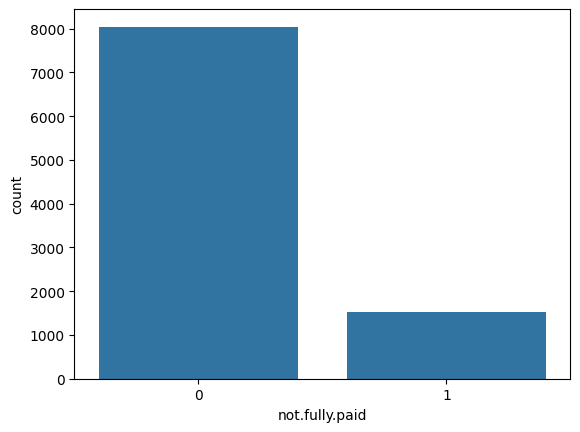

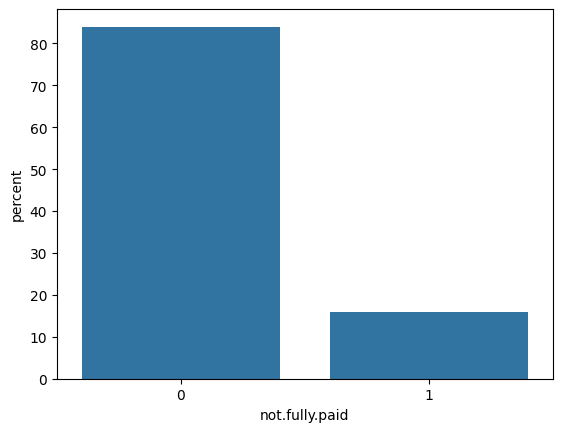

In [15]:
sns.countplot(data=df1, x='not.fully.paid')
plt.show()

sns.countplot(data=df1, x='not.fully.paid', stat='percent')
plt.show()

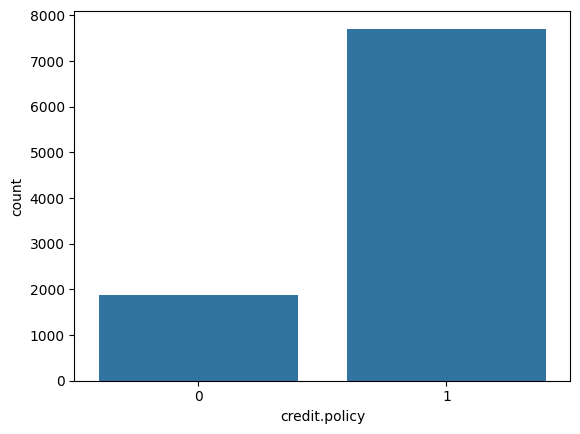

In [16]:
# conhecendo a variável de critério da empresa
sns.countplot(data=df1, x='credit.policy')
plt.show()

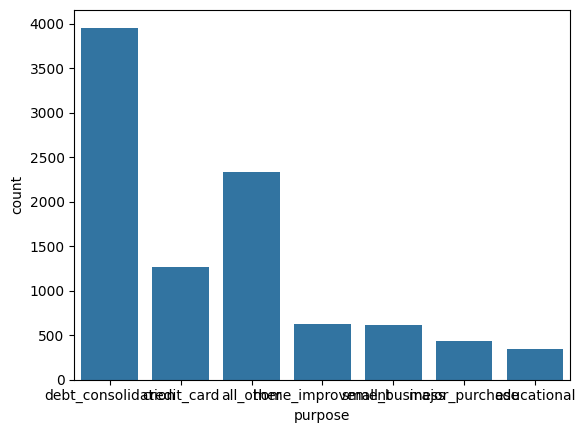

In [17]:
# conhecendo a variável objetivo do empréstimo.
sns.countplot(data=df1, x='purpose')
plt.show()

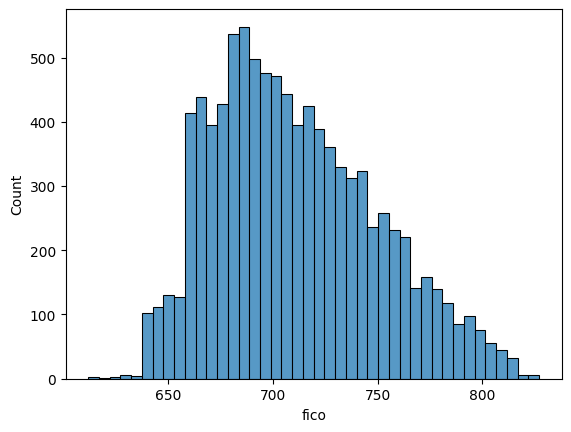

In [18]:
# conhecendo a variável fico (tipo score)
sns.histplot(data=df1, x='fico')
plt.show()

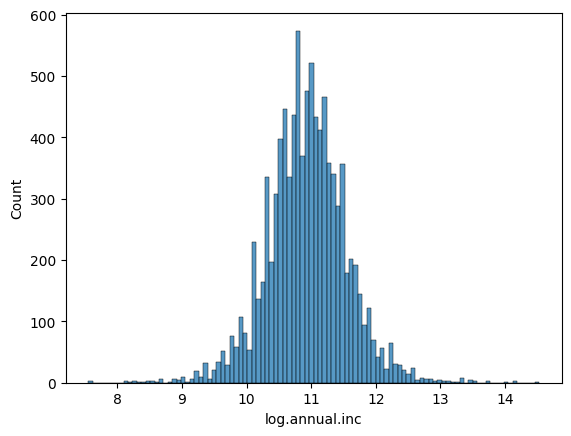

In [19]:
# conhecendo a variável renda auto declarada (log natural)
sns.histplot(data=df1, x='log.annual.inc')
plt.show()

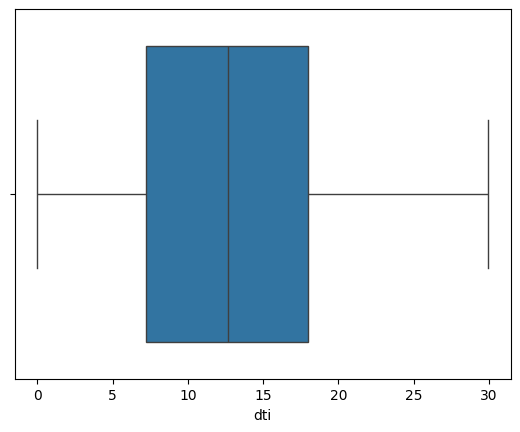

In [20]:
# conhecendo a variável comprometimento de renda
sns.boxplot(data=df1, x='dti')
plt.show()

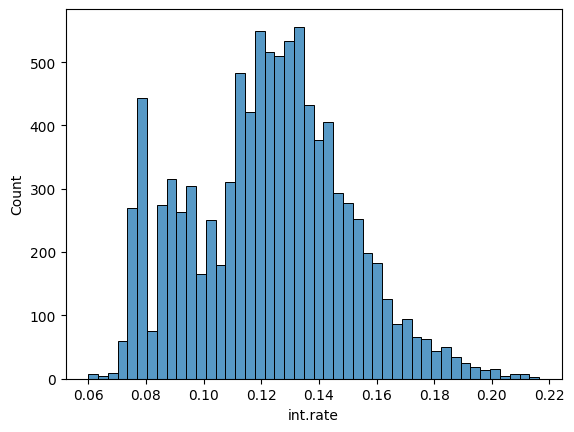

In [21]:
# conhecendo a variável taxa de juros
sns.histplot(data=df1, x='int.rate')
plt.show()

## Análise Bivariada

### 1. Quais objetivos apresentam maior taxa de inadimplência?

Empréstimo para small_business apresenta maior taxa de inadimplência, seguido de empréstimo para educação.

In [22]:
resumo = (
    df1.groupby('purpose')
       .agg(
           total_emprestimos=('not.fully.paid', 'count'),
           inadimplentes=('not.fully.paid', 'sum'),
           taxa_inadimplencia=('not.fully.paid', 'mean')
       )
       .assign(taxa_inadimplencia=lambda x: (x['taxa_inadimplencia']*100).round(1))
       .sort_values('taxa_inadimplencia', ascending=False)
)

resumo

,total_emprestimos,inadimplentes,taxa_inadimplencia
purpose,,,
small_business,619,172,27.8
educational,343,69,20.1
home_improvement,629,107,17.0
all_other,2331,387,16.6
debt_consolidation,3957,603,15.2
credit_card,1262,146,11.6
major_purchase,437,49,11.2


Text(0.5, 0, 'Objetivo do empréstimo')

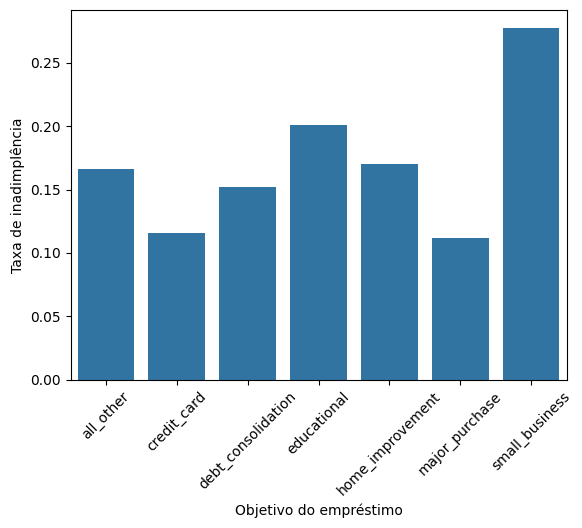

In [23]:
sns.barplot(
    data=df1.groupby('purpose', as_index=False)['not.fully.paid'].mean(),
    x='purpose',
    y='not.fully.paid'
)

plt.xticks(rotation=45)
plt.ylabel('Taxa de inadimplência')
plt.xlabel('Objetivo do empréstimo')

In [24]:
df_inadim = df1.loc[df1['not.fully.paid'] == 1, :]

In [25]:
df_inadim.shape

(1533, 14)

In [26]:
df_inadim.head()

,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
6,1,debt_consolidation,0.1496,194.02,10.714418,4.00,667,3180.041667,3839,76.8,0,0,1,1
7,1,all_other,0.1114,131.22,11.002100,11.08,722,5116.000000,24220,68.6,0,0,0,1
57,1,credit_card,0.1343,678.08,11.884489,10.15,682,4209.958333,41674,74.1,0,0,0,1
65,1,all_other,0.1059,32.55,10.433822,14.47,687,1110.000000,4485,36.9,1,0,0,1
73,1,small_business,0.1501,225.37,12.269047,6.45,677,6240.000000,56411,75.3,0,0,0,1


In [27]:
df_inadim.groupby('purpose')['not.fully.paid'] \
   .count() \
   .sort_values(ascending=False) \
   .reset_index(name='qtd_inadimplencia')

,purpose,qtd_inadimplencia
0,debt_consolidation,603
1,all_other,387
2,small_business,172
3,credit_card,146
4,home_improvement,107
5,educational,69
6,major_purchase,49


In [28]:
df_inadim['purpose'].count()

np.int64(1533)

### 2. Renda x pagar ou não

Apesar do desbalanceamento dos dados, não há evidência de diferença na renda auto declarada de quem pagou ou não o empréstimo

In [29]:
df1['log.annual.inc'].describe()

count    9578.000000
mean       10.932117
std         0.614813
min         7.547502
25%        10.558414
50%        10.928884
75%        11.291293
max        14.528354
Name: log.annual.inc, dtype: float64

In [30]:
# criando faixas de renda (log natural)
bins_renda = [7.5, 8.9, 10.3, 11.7, 13.1, 14.6]

In [31]:
# criar coluna faixa_renda
df1['faixa_renda'] = pd.cut(
    df1['log.annual.inc'],
    bins=bins_renda,
    include_lowest=True
)

In [32]:
#calculo da taxa de inadimplencia
taxa_renda = (
    df1.groupby('faixa_renda', observed=False)
       .agg(
           clientes=('not.fully.paid', 'count'),
           taxa_default=('not.fully.paid', 'mean')
       )
       .reset_index()
)

taxa_renda['taxa_default'] *= 100

taxa_renda

,faixa_renda,clientes,taxa_default
0,"(7.499, 8.9]",30,30.000000
1,"(8.9, 10.3]",1144,19.667832
2,"(10.3, 11.7]",7582,15.220259
3,"(11.7, 13.1]",796,17.462312
4,"(13.1, 14.6]",26,23.076923


In [33]:
taxa_renda = (
    df1.groupby('faixa_renda', observed=False)
       .agg(
           clientes=('not.fully.paid', 'count'),
           good=('not.fully.paid', lambda x: (x == 0).sum()),
           bad=('not.fully.paid', lambda x: (x == 1).sum())
       )
       .reset_index()
)

# Distribuição de Good e Bad
taxa_renda['dist_good'] = taxa_renda['good'] / taxa_renda['good'].sum()
taxa_renda['dist_bad'] = taxa_renda['bad'] / taxa_renda['bad'].sum()

# WoE
taxa_renda['WoE'] = np.log(
    taxa_renda['dist_good'] / taxa_renda['dist_bad']
)

# IV por faixa
taxa_renda['IV'] = (
    (taxa_renda['dist_good'] - taxa_renda['dist_bad'])
    * taxa_renda['WoE']
)

taxa_renda.round(4)

,faixa_renda,clientes,good,bad,dist_good,dist_bad,WoE,IV
0,"(7.499, 8.9]",30,21,9,0.0026,0.0059,-0.8105,0.0026
1,"(8.9, 10.3]",1144,919,225,0.1142,0.1468,-0.2506,0.0082
2,"(10.3, 11.7]",7582,6428,1154,0.7990,0.7528,0.0596,0.0028
3,"(11.7, 13.1]",796,657,139,0.0817,0.0907,-0.1046,0.0009
4,"(13.1, 14.6]",26,20,6,0.0025,0.0039,-0.4539,0.0006


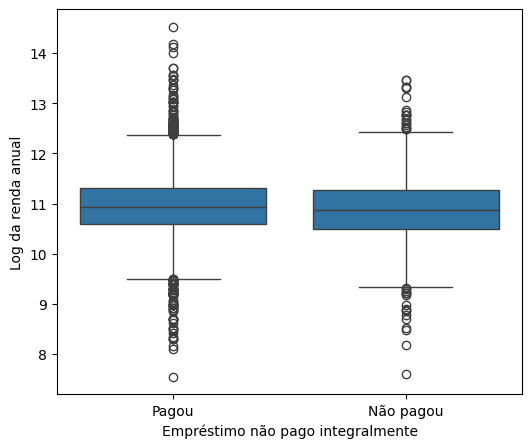

In [34]:
plt.figure(figsize=(6,5))

sns.boxplot(
    data=df1,
    x='not.fully.paid',
    y='log.annual.inc'
)

plt.xlabel('Empréstimo não pago integralmente')
plt.ylabel('Log da renda anual')
plt.xticks([0,1], ['Pagou', 'Não pagou'])
plt.show()

In [35]:
resumo = (
    df1.groupby('not.fully.paid')
       .agg(
           contagem=('log.annual.inc', 'count'),
           media=('log.annual.inc', 'mean'),
           mediana=('log.annual.inc', 'median')
       )
)

resumo

,contagem,media,mediana
not.fully.paid,,,
0,8045,10.941091,10.933178
1,1533,10.885023,10.878047


### Fico

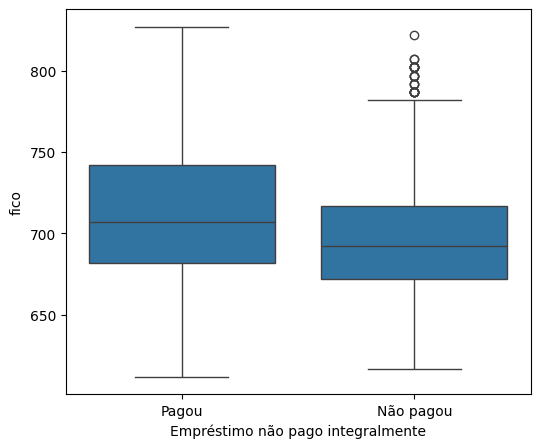

In [36]:
plt.figure(figsize=(6,5))

sns.boxplot(
    data=df1,
    x='not.fully.paid',
    y='fico'
)

plt.xlabel('Empréstimo não pago integralmente')
plt.ylabel('fico')
plt.xticks([0,1], ['Pagou', 'Não pagou'])
plt.show()

In [37]:
resumo_fico = (
    df1.groupby('not.fully.paid')
       .agg(
           contagem=('fico', 'count'),
           media=('fico', 'mean'),
           mediana=('fico', 'median')
       )
)

resumo_fico

,contagem,media,mediana
not.fully.paid,,,
0,8045,713.326911,707.0
1,1533,697.828441,692.0


In [38]:
resumo_fico = (
    df1.groupby('not.fully.paid')
       .agg(
           contagem=('fico', 'count'),
           media=('fico', 'mean'),
           q1=('fico', lambda x: x.quantile(0.25)),
           mediana=('fico', 'median'),
           q3=('fico', lambda x: x.quantile(0.75)),
           minimo=('fico', 'min'),
           maximo=('fico', 'max'),
           desvio_padrao=('fico', 'std')
       )
       .round(2)
)

resumo_fico

,contagem,media,q1,mediana,q3,minimo,maximo,desvio_padrao
not.fully.paid,,,,,,,,
0,8045,713.33,682.0,707.0,742.0,612,827,38.22
1,1533,697.83,672.0,692.0,717.0,617,822,33.76


In [39]:
# criando faixas de fico
bins = [600, 650, 700, 750, 800, 850]

# criar coluna faixa_fico
df1['faixa_fico'] = pd.cut(
    df1['fico'],
    bins=bins,
    include_lowest=True
)

In [40]:
#calculo da taxa de inadimplencia
taxa_fico = (
    df1.groupby('faixa_fico', observed=False)
       .agg(
           clientes=('not.fully.paid', 'count'),
           taxa_default=('not.fully.paid', 'mean')
       )
       .reset_index()
)

taxa_fico['taxa_default'] *= 100

taxa_fico

,faixa_fico,clientes,taxa_default
0,"(599.999, 650.0]",231,32.034632
1,"(650.0, 700.0]",3990,20.050125
2,"(700.0, 750.0]",3687,14.510442
3,"(750.0, 800.0]",1525,7.475410
4,"(800.0, 850.0]",145,6.896552


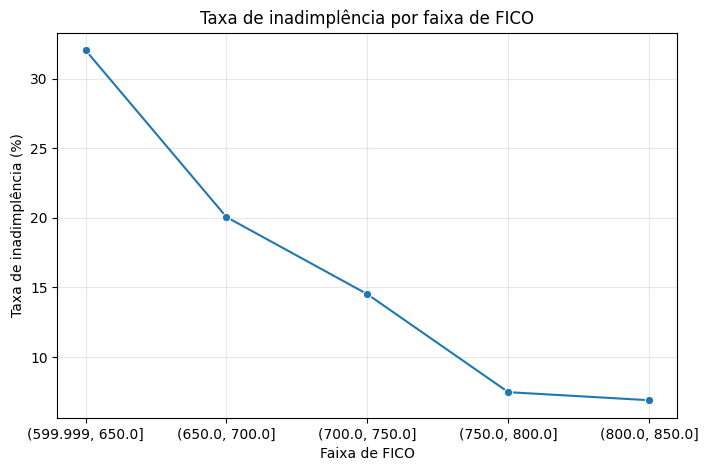

In [41]:
taxa_fico_plot = taxa_fico.copy()
taxa_fico_plot['faixa_fico'] = taxa_fico_plot['faixa_fico'].astype(str)

plt.figure(figsize=(8,5))

sns.lineplot(
    data=taxa_fico_plot,
    x='faixa_fico',
    y='taxa_default',
    marker='o'
)

plt.ylabel('Taxa de inadimplência (%)')
plt.xlabel('Faixa de FICO')
plt.title('Taxa de inadimplência por faixa de FICO')

plt.grid(alpha=0.3)
plt.show()

In [42]:
# #calculo da WoE e IV
# taxa_fico = (
#     df1.groupby('faixa_fico', observed=False)
#        .agg(
#            clientes=('not.fully.paid', 'count'),
#            taxa_default=('not.fully.paid', 'mean')
#        )
#        .reset_index()
# )

# taxa_fico['taxa_default'] *= 100
# taxa_fico['taxa_good'] = 100 - taxa_fico['taxa_default']
# taxa_fico['WoE'] = np.log10(taxa_fico['taxa_good'] / taxa_fico['taxa_default']) 

# taxa_fico

In [43]:
taxa_fico = (
    df1.groupby('faixa_fico', observed=False)
       .agg(
           clientes=('not.fully.paid', 'count'),
           good=('not.fully.paid', lambda x: (x == 0).sum()),
           bad=('not.fully.paid', lambda x: (x == 1).sum())
       )
       .reset_index()
)

# Distribuição de Good e Bad
taxa_fico['dist_good'] = taxa_fico['good'] / taxa_fico['good'].sum()
taxa_fico['dist_bad'] = taxa_fico['bad'] / taxa_fico['bad'].sum()

# WoE
taxa_fico['WoE'] = np.log(
    taxa_fico['dist_good'] / taxa_fico['dist_bad']
)

# IV por faixa
taxa_fico['IV'] = (
    (taxa_fico['dist_good'] - taxa_fico['dist_bad'])
    * taxa_fico['WoE']
)

taxa_fico.round(4)

,faixa_fico,clientes,good,bad,dist_good,dist_bad,WoE,IV
0,"(599.999, 650.0]",231,157,74,0.0195,0.0483,-0.9056,0.0260
1,"(650.0, 700.0]",3990,3190,800,0.3965,0.5219,-0.2747,0.0344
2,"(700.0, 750.0]",3687,3152,535,0.3918,0.3490,0.1157,0.0050
3,"(750.0, 800.0]",1525,1411,114,0.1754,0.0744,0.8580,0.0867
4,"(800.0, 850.0]",145,135,10,0.0168,0.0065,0.9449,0.0097


In [44]:
iv_fico = taxa_fico['IV'].sum()

print(f'IV do FICO: {iv_fico:.4f}')

IV do FICO: 0.1618


#DTI

In [45]:
df1['dti'].describe()

count    9578.000000
mean       12.606679
std         6.883970
min         0.000000
25%         7.212500
50%        12.665000
75%        17.950000
max        29.960000
Name: dti, dtype: float64

In [46]:
bins_dti = [0, 5, 10, 15, 20, 25, 30]

In [47]:
# criar coluna faixa_dti
df1['faixa_dti'] = pd.cut(
    df1['dti'],
    bins=bins_dti,
    include_lowest=True
)

In [48]:
taxa_dti = (
    df1.groupby('faixa_dti', observed=False)
       .agg(
           clientes=('not.fully.paid', 'count'),
           good=('not.fully.paid', lambda x: (x == 0).sum()),
           bad=('not.fully.paid', lambda x: (x == 1).sum())
       )
       .reset_index()
)

# Distribuição de Good e Bad
taxa_dti['dist_good'] = taxa_dti['good'] / taxa_dti['good'].sum()
taxa_dti['dist_bad'] = taxa_dti['bad'] / taxa_dti['bad'].sum()

# WoE
taxa_dti['WoE'] = np.log(
    taxa_dti['dist_good'] / taxa_dti['dist_bad']
)

# IV por faixa
taxa_dti['IV'] = (
    (taxa_dti['dist_good'] - taxa_dti['dist_bad'])
    * taxa_dti['WoE']
)

taxa_dti.round(4)

,faixa_dti,clientes,good,bad,dist_good,dist_bad,WoE,IV
0,"(-0.001, 5.0]",1601,1372,229,0.1705,0.1494,0.1325,0.0028
1,"(5.0, 10.0]",2012,1705,307,0.2119,0.2003,0.0566,0.0007
2,"(10.0, 15.0]",2271,1919,352,0.2385,0.2296,0.0381,0.0003
3,"(15.0, 20.0]",2067,1720,347,0.2138,0.2264,-0.0571,0.0007
4,"(20.0, 25.0]",1475,1215,260,0.1510,0.1696,-0.1160,0.0022
5,"(25.0, 30.0]",152,114,38,0.0142,0.0248,-0.5592,0.0059


In [49]:
#calculo da taxa de inadimplencia
taxa_dti = (
    df1.groupby('faixa_dti', observed=False)
       .agg(
           clientes=('not.fully.paid', 'count'),
           taxa_default=('not.fully.paid', 'mean')
       )
       .reset_index()
)

taxa_dti['taxa_default'] *= 100

taxa_dti

,faixa_dti,clientes,taxa_default
0,"(-0.001, 5.0]",1601,14.303560
1,"(5.0, 10.0]",2012,15.258449
2,"(10.0, 15.0]",2271,15.499780
3,"(15.0, 20.0]",2067,16.787615
4,"(20.0, 25.0]",1475,17.627119
5,"(25.0, 30.0]",152,25.000000


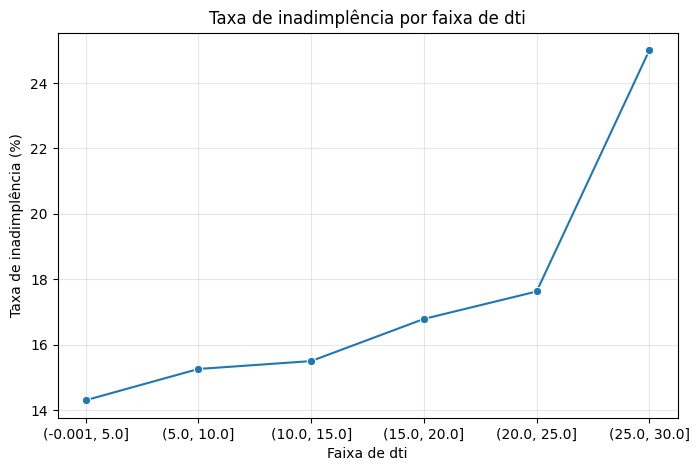

In [50]:
taxa_dti_plot = taxa_dti.copy()
taxa_dti_plot['faixa_dti'] = taxa_dti_plot['faixa_dti'].astype(str)

plt.figure(figsize=(8,5))

sns.lineplot(
    data=taxa_dti_plot,
    x='faixa_dti',
    y='taxa_default',
    marker='o'
)

plt.ylabel('Taxa de inadimplência (%)')
plt.xlabel('Faixa de dti')
plt.title('Taxa de inadimplência por faixa de dti')

plt.grid(alpha=0.3)
plt.show()

## Taxa de Juros

In [51]:
df1['int.rate'].describe()

count    9578.000000
mean        0.122640
std         0.026847
min         0.060000
25%         0.103900
50%         0.122100
75%         0.140700
max         0.216400
Name: int.rate, dtype: float64

In [52]:
bins_juros =[0.06, 0.092, 0.124, 0.156, 0.188, 0.22]

In [53]:
# criar coluna faixa_juros
df1['faixa_juros'] = pd.cut(
    df1['int.rate'],
    bins=bins_juros,
    include_lowest=True
)

In [54]:
taxa_juros = (
    df1.groupby('faixa_juros', observed=False)
       .agg(
           clientes=('not.fully.paid', 'count'),
           good=('not.fully.paid', lambda x: (x == 0).sum()),
           bad=('not.fully.paid', lambda x: (x == 1).sum())
       )
       .reset_index()
)

# Distribuição de Good e Bad
taxa_juros['dist_good'] = taxa_juros['good'] / taxa_juros['good'].sum()
taxa_juros['dist_bad'] = taxa_juros['bad'] / taxa_juros['bad'].sum()

# WoE
taxa_juros['WoE'] = np.log(
    taxa_juros['dist_good'] / taxa_juros['dist_bad']
)

# IV por faixa
taxa_juros['IV'] = (
    (taxa_juros['dist_good'] - taxa_juros['dist_bad'])
    * taxa_juros['WoE']
)

taxa_juros.round(4)

,faixa_juros,clientes,good,bad,dist_good,dist_bad,WoE,IV
0,"(0.059, 0.092]",1489,1404,85,0.1745,0.0554,1.1466,0.1365
1,"(0.092, 0.124]",3393,2904,489,0.3610,0.3190,0.1237,0.0052
2,"(0.124, 0.156]",3667,2983,684,0.3708,0.4462,-0.1851,0.0140
3,"(0.156, 0.188]",926,684,242,0.0850,0.1579,-0.6188,0.0451
4,"(0.188, 0.22]",103,70,33,0.0087,0.0215,-0.9058,0.0116


In [55]:
#calculo da taxa de inadimplencia
taxa_juros = (
    df1.groupby('faixa_juros', observed=False)
       .agg(
           clientes=('not.fully.paid', 'count'),
           taxa_default=('not.fully.paid', 'mean')
       )
       .reset_index()
)

taxa_juros['taxa_default'] *= 100

taxa_juros

,faixa_juros,clientes,taxa_default
0,"(0.059, 0.092]",1489,5.708529
1,"(0.092, 0.124]",3393,14.412025
2,"(0.124, 0.156]",3667,18.652850
3,"(0.156, 0.188]",926,26.133909
4,"(0.188, 0.22]",103,32.038835


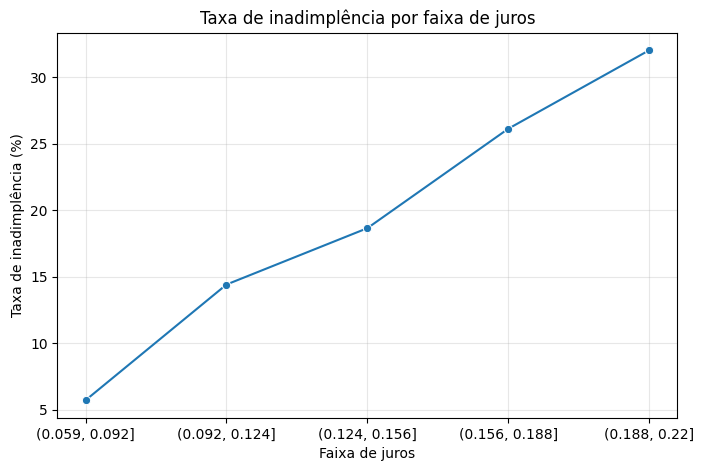

In [56]:
taxa_juros_plot = taxa_juros.copy()
taxa_juros_plot['faixa_juros'] = taxa_juros_plot['faixa_juros'].astype(str)

plt.figure(figsize=(8,5))

sns.lineplot(
    data=taxa_juros_plot,
    x='faixa_juros',
    y='taxa_default',
    marker='o'
)

plt.ylabel('Taxa de inadimplência (%)')
plt.xlabel('Faixa de juros')
plt.title('Taxa de inadimplência por faixa de juros')

plt.grid(alpha=0.3)
plt.show()

# Revol util

In [57]:
df1['revol.util'].describe()

count    9578.000000
mean       46.799236
std        29.014417
min         0.000000
25%        22.600000
50%        46.300000
75%        70.900000
max       119.000000
Name: revol.util, dtype: float64

In [58]:
bins_revol = [0, 20, 40, 60, 80 , 100, 120]

In [59]:
# criar coluna faixa_revol
df1['faixa_revol'] = pd.cut(
    df1['revol.util'],
    bins=bins_revol,
    include_lowest=True
)

In [60]:
taxa_revol = (
    df1.groupby('faixa_revol', observed=False)
       .agg(
           clientes=('not.fully.paid', 'count'),
           good=('not.fully.paid', lambda x: (x == 0).sum()),
           bad=('not.fully.paid', lambda x: (x == 1).sum())
       )
       .reset_index()
)

# Distribuição de Good e Bad
taxa_revol['dist_good'] = taxa_revol['good'] / taxa_revol['good'].sum()
taxa_revol['dist_bad'] = taxa_revol['bad'] / taxa_revol['bad'].sum()

# WoE
taxa_revol['WoE'] = np.log(
    taxa_revol['dist_good'] / taxa_revol['dist_bad']
)

# IV por faixa
taxa_revol['IV'] = (
    (taxa_revol['dist_good'] - taxa_revol['dist_bad'])
    * taxa_revol['WoE']
)

taxa_revol.round(4)

,faixa_revol,clientes,good,bad,dist_good,dist_bad,WoE,IV
0,"(-0.001, 20.0]",2173,1914,259,0.2379,0.1689,0.3423,0.0236
1,"(20.0, 40.0]",1967,1689,278,0.2099,0.1813,0.1464,0.0042
2,"(40.0, 60.0]",2054,1701,353,0.2114,0.2303,-0.0853,0.0016
3,"(60.0, 80.0]",1795,1493,302,0.1856,0.1970,-0.0597,0.0007
4,"(80.0, 100.0]",1562,1231,331,0.1530,0.2159,-0.3444,0.0217
5,"(100.0, 120.0]",27,17,10,0.0021,0.0065,-1.1272,0.0050


In [61]:
#calculo da taxa de inadimplencia
taxa_revol = (
    df1.groupby('faixa_revol', observed=False)
       .agg(
           clientes=('not.fully.paid', 'count'),
           taxa_default=('not.fully.paid', 'mean')
       )
       .reset_index()
)

taxa_revol['taxa_default'] *= 100

taxa_revol

,faixa_revol,clientes,taxa_default
0,"(-0.001, 20.0]",2173,11.919006
1,"(20.0, 40.0]",1967,14.133198
2,"(40.0, 60.0]",2054,17.185979
3,"(60.0, 80.0]",1795,16.824513
4,"(80.0, 100.0]",1562,21.190781
5,"(100.0, 120.0]",27,37.037037


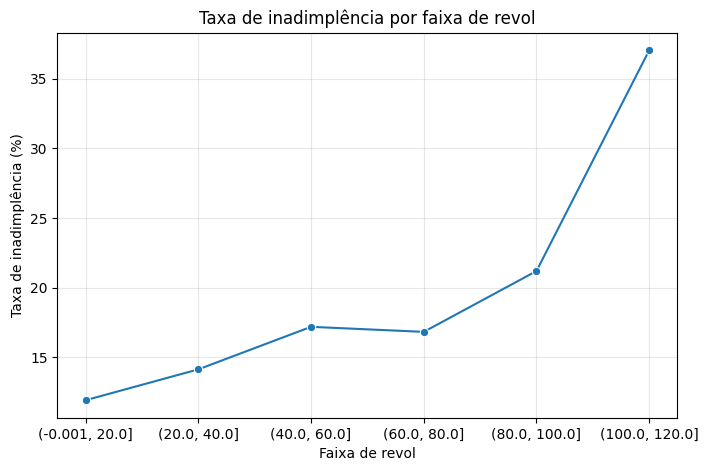

In [62]:
taxa_revol_plot = taxa_revol.copy()
taxa_revol_plot['faixa_revol'] = taxa_revol_plot['faixa_revol'].astype(str)

plt.figure(figsize=(8,5))

sns.lineplot(
    data=taxa_revol_plot,
    x='faixa_revol',
    y='taxa_default',
    marker='o'
)

plt.ylabel('Taxa de inadimplência (%)')
plt.xlabel('Faixa de revol')
plt.title('Taxa de inadimplência por faixa de revol')

plt.grid(alpha=0.3)
plt.show()

# Análise Multivariada

In [63]:
df1.dtypes

credit.policy           int64
purpose                   str
int.rate              float64
installment           float64
log.annual.inc        float64
dti                   float64
fico                    int64
days.with.cr.line     float64
revol.bal               int64
revol.util            float64
inq.last.6mths          int64
delinq.2yrs             int64
pub.rec                 int64
not.fully.paid          int64
faixa_renda          category
faixa_fico           category
faixa_dti            category
faixa_juros          category
faixa_revol          category
dtype: object

In [64]:
cols_drop = ['purpose', 'faixa_renda', 'faixa_fico', 'faixa_dti', 'faixa_juros', 'faixa_revol' ]

In [65]:
df_num = df1.drop(columns=cols_drop)

In [66]:
df_num.dtypes

credit.policy          int64
int.rate             float64
installment          float64
log.annual.inc       float64
dti                  float64
fico                   int64
days.with.cr.line    float64
revol.bal              int64
revol.util           float64
inq.last.6mths         int64
delinq.2yrs            int64
pub.rec                int64
not.fully.paid         int64
dtype: object

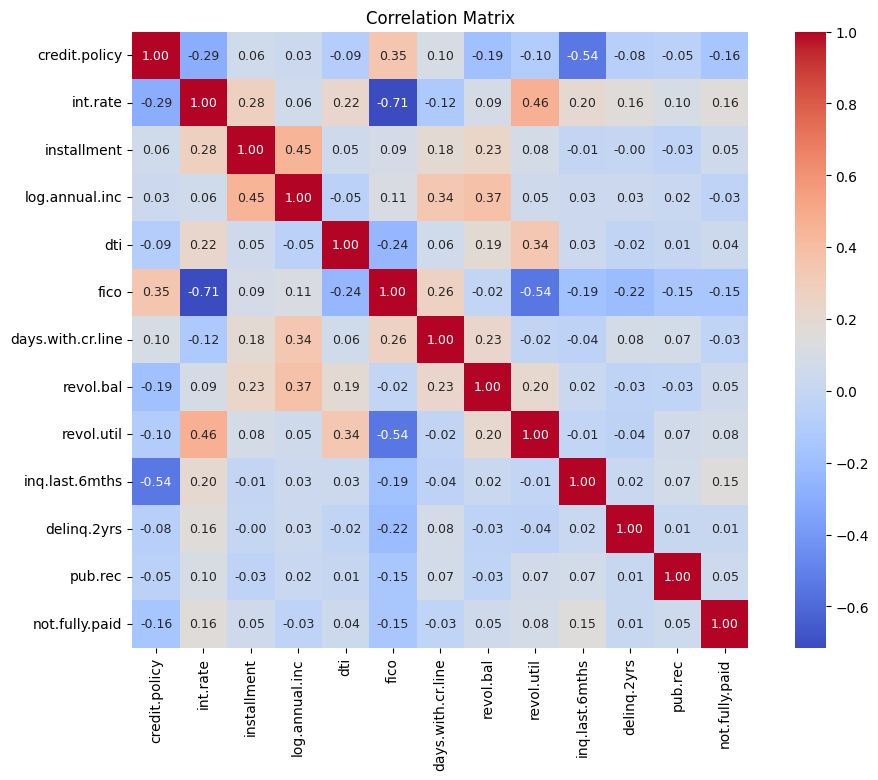

In [67]:
correlation = df_num.corr( method='pearson' )

plt.figure(figsize=(12,8))

sns.heatmap(
    correlation,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    square=True,
    annot_kws={"size": 9}
)

plt.title('Correlation Matrix')
plt.show()

A matriz de correlação indica que as variáveis credit.policy, fico, int.rate e inq.last.6mths apresentam as relações mais relevantes com a inadimplência, embora todas sejam de magnitude moderada (|r| ≤ 0,16). Esse resultado é esperado em problemas de risco de crédito, nos quais o default depende da combinação de diversos fatores e não de uma única variável. Entre as features explicativas, destaca-se a forte correlação negativa entre fico e int.rate (-0,71), refletindo a política de precificação da LendingClub: clientes com melhor score recebem taxas de juros menores. Como essa relação pode introduzir multicolinearidade em modelos lineares, ela será investigada posteriormente com o VIF. Para modelos baseados em árvores, como Random Forest, essas correlações tendem a ter impacto reduzido, permitindo manter as variáveis na etapa inicial da modelagem e avaliar sua contribuição por meio de Feature Importance e SHAP.

Fazer o VIF para multicolinearidade

## VIF

In [68]:
df_num.columns

Index(['credit.policy', 'int.rate', 'installment', 'log.annual.inc', 'dti',
       'fico', 'days.with.cr.line', 'revol.bal', 'revol.util',
       'inq.last.6mths', 'delinq.2yrs', 'pub.rec', 'not.fully.paid'],
      dtype='str')

In [69]:
X_vif = df_num.drop('not.fully.paid', axis=1)

In [70]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

In [71]:
# vif = pd.DataFrame()

# vif['feature'] = X_vif.columns

# vif['VIF'] = [
#     variance_inflation_factor(X_vif.values, i)
#     for i in range(X_vif.shape[1])
# ]

# vif = vif.sort_values('VIF', ascending=False)

# print(vif)

In [72]:
X_vif_const = add_constant(X_vif)

vif = pd.DataFrame({
    'feature': X_vif_const.columns,
    'VIF': [variance_inflation_factor(X_vif_const.values, i)
            for i in range(X_vif_const.shape[1])]
})

vif = vif[vif['feature'] != 'const']
vif = vif.sort_values('VIF', ascending=False)

print(vif)

              feature       VIF
6                fico  3.319104
2            int.rate  2.740399
9          revol.util  1.725801
1       credit.policy  1.661680
3         installment  1.602319
4      log.annual.inc  1.529215
10     inq.last.6mths  1.457600
8           revol.bal  1.364227
7   days.with.cr.line  1.305100
5                 dti  1.197613
11        delinq.2yrs  1.139626
12            pub.rec  1.048510


train_test_split(stratify=y);

calcular IV apenas no treino;

ajustar a L1 apenas no treino;

calcular Permutation Importance no conjunto de teste (ou em cada fold do StratifiedKFold).

# Split do dataset

In [73]:
df2 = df1.copy()

In [74]:
df2.columns

Index(['credit.policy', 'purpose', 'int.rate', 'installment', 'log.annual.inc',
       'dti', 'fico', 'days.with.cr.line', 'revol.bal', 'revol.util',
       'inq.last.6mths', 'delinq.2yrs', 'pub.rec', 'not.fully.paid',
       'faixa_renda', 'faixa_fico', 'faixa_dti', 'faixa_juros', 'faixa_revol'],
      dtype='str')

In [75]:
df2 = df2.drop(['faixa_renda', 'faixa_fico', 'faixa_dti', 'faixa_juros', 'faixa_revol'], axis=1)

In [76]:
df2.columns

Index(['credit.policy', 'purpose', 'int.rate', 'installment', 'log.annual.inc',
       'dti', 'fico', 'days.with.cr.line', 'revol.bal', 'revol.util',
       'inq.last.6mths', 'delinq.2yrs', 'pub.rec', 'not.fully.paid'],
      dtype='str')

In [77]:
X = df2.drop('not.fully.paid', axis=1)
y = df2['not.fully.paid']

In [78]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

In [79]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(7662, 13)
(7662,)
(1916, 13)
(1916,)


## Calculo WoE/IV

In [80]:
df_train = X_train.copy()
df_train['not.fully.paid'] = y_train

In [81]:
# X_test['faixa_fico'] = pd.cut(
#     X_test['fico'],
#     bins=bin_edges,
#     include_lowest=True
# )

In [82]:
df_test = X_test.copy()
df_test['not.fully.paid'] = y_test

In [83]:
df_test.head()

,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
8157,0,debt_consolidation,0.1551,418.99,11.034890,15.38,647,1860.000000,11214,70.1,0,0,0,0
1928,1,debt_consolidation,0.0800,58.76,10.819778,19.06,732,4773.000000,27835,45.8,0,0,0,0
2779,1,all_other,0.1379,681.51,11.842200,7.12,712,5100.000000,7629,25.3,0,0,0,0
2520,1,all_other,0.1284,64.72,9.615805,10.48,702,2321.958333,653,3.7,1,0,0,0
2601,1,home_improvement,0.1568,350.02,10.950807,7.62,682,2850.000000,1815,34.2,2,0,0,1


In [84]:
var = X_train.columns

In [85]:
# bins = pd.qcut(
#     X_train[var],
#     q=5,
#     retbins=True, # retorna os bins
#     duplicates='drop'
# )

In [86]:
def calculate_woe_iv(df, feature, target, n_bins=5):
    
    data = df[[feature, target]].copy()

    # 1. Criar bins
    if pd.api.types.is_numeric_dtype(data[feature]):
        
        data['bin'] = pd.qcut(
            data[feature],
            q=n_bins,
            duplicates='drop'
        )
    
    # Variável categórica
    else:
        data['bin'] = data[feature].fillna('Missing')

    # 2. Agrupar Good e Bad
    grouped = (
        data
        .groupby('bin', observed=True)[target]
        .agg(
            total='count',
            bad='sum'
        )
        .reset_index()
    )

    # 3. Calcular Good
    grouped['good'] = grouped['total'] - grouped['bad']

    # 4. Totais
    total_good = grouped['good'].sum()
    total_bad = grouped['bad'].sum()

    # 5. Distribuição Good e Bad
    grouped['dist_good'] = grouped['good'] / total_good
    grouped['dist_bad'] = grouped['bad'] / total_bad

    # 6. Evitar divisão por zero
    epsilon = 0.000001

    grouped['dist_good'] = grouped['dist_good'].clip(lower=epsilon)
    grouped['dist_bad'] = grouped['dist_bad'].clip(lower=epsilon)

    # 7. WoE
    grouped['woe'] = np.log(
        grouped['dist_good'] / grouped['dist_bad']
    )

    # 8. IV por bin
    grouped['iv'] = (
        (grouped['dist_good'] - grouped['dist_bad'])
        * grouped['woe']
    )

    # 9. IV total da variável
    iv_total = grouped['iv'].sum()

    # 10. Identificação da variável
    grouped.insert(0, 'feature', feature)

    return grouped, iv_total

In [87]:
def calculate_woe_iv_all(
    df,
    target,
    n_bins=5
):
    
    woe_tables = []
    iv_summary = []
    
    features = [col for col in df.columns if col != target]
    
    for feature in features:
        
        woe_table, iv_total = calculate_woe_iv(
            df=df,
            feature=feature,
            target=target,
            n_bins=n_bins
        )
        
        woe_tables.append(woe_table)
        
        iv_summary.append({
            'feature': feature,
            'iv': iv_total
        })
    
    
    df_woe_iv = pd.concat(
        woe_tables,
        ignore_index=True
    )
    
    df_iv = (
        pd.DataFrame(iv_summary)
        .sort_values(
            'iv',
            ascending=False
        )
        .reset_index(drop=True)
    )
    
    return df_woe_iv, df_iv

In [88]:
df_woe_iv, df_iv = calculate_woe_iv_all(
    df_train,
    target='not.fully.paid',
    n_bins=5
)

In [89]:
df_woe_iv

,feature,bin,total,bad,good,dist_good,dist_bad,woe,iv
0,credit.policy,"(-0.001, 1.0]",7662,1226,6436,1.000000,1.000000,0.000000,0.000000
1,purpose,all_other,1892,312,1580,0.245494,0.254486,-0.035973,0.000323
2,purpose,credit_card,998,115,883,0.137197,0.093801,0.380243,0.016501
3,purpose,debt_consolidation,3144,484,2660,0.413300,0.394780,0.045846,0.000849
4,purpose,educational,278,52,226,0.035115,0.042414,-0.188859,0.001379
5,purpose,home_improvement,491,87,404,0.062772,0.070962,-0.122644,0.001005
6,purpose,major_purchase,353,35,318,0.049410,0.028548,0.548553,0.011444
7,purpose,small_business,506,141,365,0.056712,0.115008,-0.707013,0.041216
8,int.rate,"(0.059, 0.0963]",1578,105,1473,0.228869,0.085644,0.982946,0.140782
9,int.rate,"(0.0963, 0.117]",1487,230,1257,0.195308,0.187602,0.040254,0.000310


In [90]:
df_iv

,feature,iv
0,int.rate,0.205157
1,fico,0.168732
2,inq.last.6mths,0.132084
3,purpose,0.072716
4,revol.util,0.053275
5,installment,0.017984
6,revol.bal,0.015106
7,dti,0.012836
8,log.annual.inc,0.007704
9,days.with.cr.line,0.001435


In [91]:
def get_variable_type(series):
    
    # Categórica
    if series.dtype == 'object':
        return 'categorical'
    
    # Numérica
    if pd.api.types.is_numeric_dtype(series):
        
        n_unique = series.nunique()
        
        # Binária
        if n_unique == 2:
            return 'binary'
        
        # Discreta / contagem
        if pd.api.types.is_integer_dtype(series):
            return 'discrete'
        
        # Contínua
        return 'continuous'
    
    return 'categorical'

In [92]:
for feature in df_train.columns:
    
    if feature != 'not.fully.paid':
        print(feature, get_variable_type(df_train[feature]))

credit.policy binary
purpose categorical
int.rate continuous
installment continuous
log.annual.inc continuous
dti continuous
fico discrete
days.with.cr.line continuous
revol.bal discrete
revol.util continuous
inq.last.6mths discrete
delinq.2yrs discrete
pub.rec discrete


In [93]:
variable_types = {
    'credit.policy': 'binary',
    'purpose': 'categorical',

    'int.rate': 'continuous',
    'installment': 'continuous',
    'log.annual.inc': 'continuous',
    'dti': 'continuous',
    'fico': 'continuous',
    'days.with.cr.line': 'continuous',
    'revol.bal': 'continuous',
    'revol.util': 'continuous',

    'inq.last.6mths': 'discrete',
    'delinq.2yrs': 'discrete',
    'pub.rec': 'discrete'
}

In [94]:
discrete_bins = {
    'inq.last.6mths': [-1, 0, 1, 2, np.inf],
    'delinq.2yrs': [-1, 0, 1, np.inf],
    'pub.rec': [-1, 0, np.inf]
}

In [95]:
# def calculate_woe_iv(
#     df,
#     feature,
#     target,
#     variable_types,
#     n_bins=5
# ):
    
#     data = df[[feature, target]].copy()
    
#     variable_type = variable_types[feature]
    
#     # -----------------------------
#     # Continuous
#     # -----------------------------
    
#     if variable_type == 'continuous':
        
#         data['bin'] = pd.qcut(
#             data[feature],
#             q=n_bins,
#             duplicates='drop'
#         )
    
#     # -----------------------------
#     # Binary / categorical
#     # -----------------------------
    
#     elif variable_type in ['binary', 'categorical']:
        
#         data['bin'] = data[feature].fillna(
#             'Missing'
#         )
   
    
#     # -----------------------------
#     # Discrete
#     # -----------------------------
    
#     elif variable_type == 'discrete':
    
#         data['bin'] = pd.cut(
#             data[feature],
#             bins=discrete_bins[feature]
#         )
    
#     else:
#         raise ValueError(
#             f'Tipo desconhecido: {variable_type}'
#         )

In [96]:
def calculate_woe_iv(
    df,
    feature,
    target,
    variable_types,
    discrete_bins,
    n_bins=5
):
    
    data = df[[feature, target]].copy()
    
    variable_type = variable_types[feature]
    
    # -----------------------------
    # Continuous
    # -----------------------------
    
    if variable_type == 'continuous':
        
        data['bin'] = pd.qcut(
            data[feature],
            q=n_bins,
            duplicates='drop'
        )
    
    # -----------------------------
    # Binary / categorical
    # -----------------------------
    
    elif variable_type in ['binary', 'categorical']:
        
        data['bin'] = data[feature].fillna(
            'Missing'
        )
   
    
    # -----------------------------
    # Discrete
    # -----------------------------
    
    elif variable_type == 'discrete':
    
        data['bin'] = pd.cut(
            data[feature],
            bins=discrete_bins[feature]
        )
    
    else:
        raise ValueError(
            f'Tipo desconhecido: {variable_type}'
        )

    # 2. Agrupar Good e Bad
    grouped = (
        data
        .groupby('bin', observed=True)[target]
        .agg(
            total='count',
            bad='sum'
        )
        .reset_index()
    )

    # 3. Calcular Good
    grouped['good'] = grouped['total'] - grouped['bad']

    # 4. Totais
    total_good = grouped['good'].sum()
    total_bad = grouped['bad'].sum()
    grouped['bad_rate'] = (grouped['bad'] / grouped['total']
)

    # 5. Distribuição Good e Bad
    grouped['dist_good'] = grouped['good'] / total_good
    grouped['dist_bad'] = grouped['bad'] / total_bad

    # 6. Evitar divisão por zero
    epsilon = 0.000001

    grouped['dist_good'] = grouped['dist_good'].clip(lower=epsilon)
    grouped['dist_bad'] = grouped['dist_bad'].clip(lower=epsilon)

    # 7. WoE
    grouped['woe'] = np.log(
        grouped['dist_good'] / grouped['dist_bad']
    )

    # 8. IV por bin
    grouped['iv'] = (
        (grouped['dist_good'] - grouped['dist_bad'])
        * grouped['woe']
    )

    # 9. IV total da variável
    iv_total = grouped['iv'].sum()

    # 10. Identificação da variável
    grouped.insert(0, 'feature', feature)

    return grouped, iv_total

In [97]:
def calculate_woe_iv_all(
    df,
    target,
    variable_types,
    discrete_bins,
    n_bins=5
):
    
    woe_tables = []
    iv_summary = []
    
    features = [col for col in df.columns if col != target]
    
    for feature in features:
        
        woe_table, iv_total = calculate_woe_iv(
            df=df,
            feature=feature,
            target=target,
            variable_types=variable_types,
            discrete_bins=discrete_bins,
            n_bins=n_bins
        )
        
        woe_tables.append(woe_table)
        
        iv_summary.append({
            'feature': feature,
            'iv': iv_total
        })
    
    
    df_woe_iv = pd.concat(
        woe_tables,
        ignore_index=True
    )
    
    df_iv = (
        pd.DataFrame(iv_summary)
        .sort_values(
            'iv',
            ascending=False
        )
        .reset_index(drop=True)
    )
    
    return df_woe_iv, df_iv

In [98]:
df_woe_iv, df_iv = calculate_woe_iv_all(
    df_train,
    target='not.fully.paid',
    variable_types=variable_types,
    discrete_bins=discrete_bins,
    n_bins=5
)

In [99]:
pd.set_option('display.max_rows', None)

df_woe_iv

,feature,bin,total,bad,good,bad_rate,dist_good,dist_bad,woe,iv
0,credit.policy,0,1491,416,1075,0.279007,0.167029,0.339315,-0.708760,0.122109
1,credit.policy,1,6171,810,5361,0.131259,0.832971,0.660685,0.231721,0.039922
2,purpose,all_other,1892,312,1580,0.164905,0.245494,0.254486,-0.035973,0.000323
3,purpose,credit_card,998,115,883,0.115230,0.137197,0.093801,0.380243,0.016501
4,purpose,debt_consolidation,3144,484,2660,0.153944,0.413300,0.394780,0.045846,0.000849
5,purpose,educational,278,52,226,0.187050,0.035115,0.042414,-0.188859,0.001379
6,purpose,home_improvement,491,87,404,0.177189,0.062772,0.070962,-0.122644,0.001005
7,purpose,major_purchase,353,35,318,0.099150,0.049410,0.028548,0.548553,0.011444
8,purpose,small_business,506,141,365,0.278656,0.056712,0.115008,-0.707013,0.041216
9,int.rate,"(0.059, 0.0963]",1578,105,1473,0.066540,0.228869,0.085644,0.982946,0.140782


In [100]:
df_iv

,feature,iv
0,int.rate,0.205157
1,fico,0.168732
2,credit.policy,0.162031
3,inq.last.6mths,0.143010
4,purpose,0.072716
5,revol.util,0.053275
6,pub.rec,0.021457
7,installment,0.017984
8,revol.bal,0.015106
9,dti,0.012836


## Regressão Logistica

In [101]:
purpose_woe = {
    'all_other': -0.035973,
    'credit_card': 0.380243,
    'debt_consolidation': 0.045846,
    'educational': -0.188859,
    'home_improvement': -0.122644,
    'major_purchase': 0.548553,
    'small_business': -0.707013
}

In [102]:
# df_test = X_test.copy()
# df_test['not.fully.paid'] = y_test

In [103]:
df_test.head()

,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
8157,0,debt_consolidation,0.1551,418.99,11.034890,15.38,647,1860.000000,11214,70.1,0,0,0,0
1928,1,debt_consolidation,0.0800,58.76,10.819778,19.06,732,4773.000000,27835,45.8,0,0,0,0
2779,1,all_other,0.1379,681.51,11.842200,7.12,712,5100.000000,7629,25.3,0,0,0,0
2520,1,all_other,0.1284,64.72,9.615805,10.48,702,2321.958333,653,3.7,1,0,0,0
2601,1,home_improvement,0.1568,350.02,10.950807,7.62,682,2850.000000,1815,34.2,2,0,0,1


In [104]:
df_train['purpose'] = df_train['purpose'].map(purpose_woe)
df_test['purpose'] = df_test['purpose'].map(purpose_woe)

In [105]:
df_train.shape

(7662, 14)

In [106]:
df_test.shape

(1916, 14)

In [107]:
X_logis_train = df_train.drop('not.fully.paid', axis=1)
y_logis_train = df_train['not.fully.paid']

In [108]:
from sklearn.preprocessing import StandardScaler

# Scaling
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_logis_train)

# Logistic Regression L1
model = LogisticRegression(
    penalty='l1',
    C=0.1,
    solver='liblinear',
    random_state=42
)

model.fit(X_scaled, y_logis_train)

# Coefficients
coef = pd.Series(
    model.coef_[0],
    index=X_logis_train.columns
).sort_values()

coef

/home/deivisson/.pyenv/versions/3.13.1/envs/rossmann/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/deivisson/.pyenv/versions/3.13.1/envs/rossmann/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


fico                -0.278548
purpose             -0.248390
log.annual.inc      -0.193879
credit.policy       -0.142801
delinq.2yrs         -0.020831
dti                  0.000000
days.with.cr.line    0.036340
pub.rec              0.048833
revol.util           0.058309
int.rate             0.062958
revol.bal            0.087473
inq.last.6mths       0.181730
installment          0.184374
dtype: float64

In [109]:
X_scaled

array([[ 0.49154247,  1.36267942,  0.74453436, ..., -0.26263123,
         1.59197119, -0.2386878 ],
       [ 0.49154247,  1.36267942, -1.77994589, ..., -0.72607677,
        -0.3026674 , -0.2386878 ],
       [ 0.49154247,  0.08597611, -0.91227268, ..., -0.72607677,
         1.59197119, -0.2386878 ],
       ...,
       [ 0.49154247,  0.08597611, -1.71636639, ...,  0.2008143 ,
        -0.3026674 , -0.2386878 ],
       [ 0.49154247, -2.78838455, -0.14183871, ..., -0.72607677,
        -0.3026674 , -0.2386878 ],
       [ 0.49154247,  0.08597611,  0.74453436, ...,  0.66425983,
        -0.3026674 , -0.2386878 ]], shape=(7662, 13))

In [110]:
features_selecionadas = coef[coef != 0]

features_eliminadas = coef[coef == 0]

In [111]:
print(features_selecionadas)

fico                -0.278548
purpose             -0.248390
log.annual.inc      -0.193879
credit.policy       -0.142801
delinq.2yrs         -0.020831
days.with.cr.line    0.036340
pub.rec              0.048833
revol.util           0.058309
int.rate             0.062958
revol.bal            0.087473
inq.last.6mths       0.181730
installment          0.184374
dtype: float64


In [112]:
print(features_eliminadas)

dti    0.0
dtype: float64


In [113]:
C_values = [0.01, 0.05, 0.1, 0.2, 0.5, 1]

for C in C_values:

    model = LogisticRegression(
        penalty='l1',
        C=C,
        solver='liblinear',
        random_state=42
    )

    model.fit(X_scaled, y_logis_train)

    coef = pd.Series(
        model.coef_[0],
        index=X_logis_train.columns
    )

    selecionadas = coef[coef != 0].index.tolist()

    print(f'C={C}:')
    print(selecionadas)
    print()

C=0.01:
['credit.policy', 'purpose', 'int.rate', 'installment', 'fico', 'revol.bal', 'inq.last.6mths']

C=0.05:
['credit.policy', 'purpose', 'int.rate', 'installment', 'log.annual.inc', 'fico', 'days.with.cr.line', 'revol.bal', 'revol.util', 'inq.last.6mths', 'delinq.2yrs', 'pub.rec']

C=0.1:
['credit.policy', 'purpose', 'int.rate', 'installment', 'log.annual.inc', 'fico', 'days.with.cr.line', 'revol.bal', 'revol.util', 'inq.last.6mths', 'delinq.2yrs', 'pub.rec']

C=0.2:
['credit.policy', 'purpose', 'int.rate', 'installment', 'log.annual.inc', 'dti', 'fico', 'days.with.cr.line', 'revol.bal', 'revol.util', 'inq.last.6mths', 'delinq.2yrs', 'pub.rec']



/home/deivisson/.pyenv/versions/3.13.1/envs/rossmann/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/deivisson/.pyenv/versions/3.13.1/envs/rossmann/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/deivisson/.pyenv/versions/3.13.1/envs/rossmann/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_

C=0.5:
['credit.policy', 'purpose', 'int.rate', 'installment', 'log.annual.inc', 'dti', 'fico', 'days.with.cr.line', 'revol.bal', 'revol.util', 'inq.last.6mths', 'delinq.2yrs', 'pub.rec']

C=1:
['credit.policy', 'purpose', 'int.rate', 'installment', 'log.annual.inc', 'dti', 'fico', 'days.with.cr.line', 'revol.bal', 'revol.util', 'inq.last.6mths', 'delinq.2yrs', 'pub.rec']



In [114]:
# # define
# model = LogisticRegression(
#     penalty='l1',
#     C=0.1,
#     solver='liblinear',
#     random_state=42
# )

# # training
# model.fit(X_logis_train_scaled, y_logis_train)

In [115]:
# coef = pd.Series(
#     model.coef_[0],
#     index=X_logis_train.columns,
# ).sort_values()

# print('Features selecionadas:')
# print(coef[coef != 0])

# print('\nFeatures eliminadas:')
# print(coef[coef == 0])

eatures selecionadas:
purpose             -8.782866e-01
credit.policy       -4.432164e-01
log.annual.inc      -4.026975e-02
fico                -2.316113e-03
days.with.cr.line   -1.060065e-05
revol.bal            8.830314e-07
installment          6.857331e-04
dti                  4.250312e-03
revol.util           6.435698e-03
inq.last.6mths       9.690262e-02
pub.rec              1.544858e-01
dtype: float64

Features eliminadas:
int.rate       0.0
delinq.2yrs    0.0
dtype: float64

In [116]:
X_logis_test = df_test.drop('not.fully.paid', axis=1)
y_logis_test = df_test['not.fully.paid']

In [117]:
X_train_13 = X_logis_train.copy()
X_train_12 = X_logis_train.drop('dti', axis=1)
X_train_min = X_logis_train.drop(['dti', 'installment', 'revol.bal', 'log.annual.inc', 'delinq.2yrs', 'days.with.cr.line'],  axis=1)

X_test_13 = X_logis_test.copy()
X_test_12 = X_logis_test.drop('dti', axis=1)
X_test_min = X_logis_test.drop(['dti', 'installment', 'revol.bal', 'log.annual.inc', 'delinq.2yrs', 'days.with.cr.line'],  axis=1)



In [118]:
X_test_min.columns

Index(['credit.policy', 'purpose', 'int.rate', 'fico', 'revol.util',
       'inq.last.6mths', 'pub.rec'],
      dtype='str')

In [119]:
# Scaling
scaler_13 = StandardScaler()

X_scaled_13_train = scaler.fit_transform(X_train_13)
X_scaled_13_test = scaler.fit_transform(X_test_13)

scaler_12 = StandardScaler()

X_scaled_12_train = scaler.fit_transform(X_train_12)
X_scaled_12_test = scaler.fit_transform(X_test_12)

scaler_min = StandardScaler()

X_scaled_min_train = scaler.fit_transform(X_train_min)
X_scaled_min_test = scaler.fit_transform(X_test_min)


In [120]:
y_train.shape

(7662,)

In [121]:
# define
model_13 = LogisticRegression(max_iter=1000)

# training
model_13.fit(X_scaled_13_train, y_train)

# performance
yhat_13 = model_13.predict(X_scaled_13_test)

print('MODELO 13')
print ('Acuracia: {}'.format(mt.accuracy_score( y_test, yhat_13)))
print ('Precisao: {}'.format(mt.precision_score( y_test, yhat_13)))
print ('Recall: {}'.format(mt.recall_score( y_test, yhat_13)))
print ('F1-Score: {}'.format(mt.f1_score( y_test, yhat_13)))

MODELO 13
Acuracia: 0.8408141962421712
Precisao: 0.5384615384615384
Recall: 0.04560260586319218
F1-Score: 0.08408408408408409


In [122]:
# define
model_min = LogisticRegression(max_iter=1000)

# training
model_min.fit(X_scaled_min_train, y_train)

# performance
yhat_min = model_min.predict(X_scaled_min_test)

print('MODELO MIN')
print ('Acuracia: {}'.format(mt.accuracy_score( y_test, yhat_min)))
print ('Precisao: {}'.format(mt.precision_score( y_test, yhat_min)))
print ('Recall: {}'.format(mt.recall_score( y_test, yhat_min)))
print ('F1-Score: {}'.format(mt.f1_score( y_test, yhat_min)))

MODELO MIN
Acuracia: 0.8402922755741128
Precisao: 0.5384615384615384
Recall: 0.02280130293159609
F1-Score: 0.04375


In [123]:
# define
model_12 = LogisticRegression(max_iter=1000)

# training
model_12.fit(X_scaled_12_train, y_train)

# performance
yhat_12 = model_12.predict(X_scaled_12_test)

print('MODELO 12')
print ('Acuracia: {}'.format(mt.accuracy_score( y_test, yhat_12)))
print ('Precisao: {}'.format(mt.precision_score( y_test, yhat_12)))
print ('Recall: {}'.format(mt.recall_score( y_test, yhat_12)))
print ('F1-Score: {}'.format(mt.f1_score( y_test, yhat_12)))

MODELO 12
Acuracia: 0.8408141962421712
Precisao: 0.5384615384615384
Recall: 0.04560260586319218
F1-Score: 0.08408408408408409


In [124]:
print(np.array_equal(yhat_13, yhat_12))
print(np.array_equal(yhat_13, yhat_min))
print(np.array_equal(yhat_12, yhat_min))

True
False
False


In [125]:
# 1. Distribuição real
print(y_test.value_counts())
print(y_test.value_counts(normalize=True))

# 2. Distribuição prevista
print(pd.Series(yhat_13).value_counts())
print(pd.Series(yhat_13).value_counts(normalize=True))

# 3. Matriz de confusão
print(confusion_matrix(y_test, yhat_13))

# 4. Probabilidades
y_prob_13 = model_13.predict_proba(X_scaled_13_test)[:, 1]

print(pd.Series(y_prob_13).describe())

not.fully.paid
0    1609
1     307
Name: count, dtype: int64
not.fully.paid
0    0.83977
1    0.16023
Name: proportion, dtype: float64
0    1890
1      26
Name: count, dtype: int64
0    0.98643
1    0.01357
Name: proportion, dtype: float64
[[1597   12]
 [ 293   14]]
count    1916.000000
mean        0.160065
std         0.093533
min         0.019319
25%         0.096369
50%         0.140128
75%         0.193921
max         0.795832
dtype: float64


AVALIAÇÃO: Logistic Regression


,Métrica,Valor
0,Accuracy,0.8408
1,Precision,0.5385
2,Recall,0.0456
3,F1-Score,0.0841
4,Specificity,0.9925
5,ROC-AUC,0.6800
6,PR-AUC,0.2966


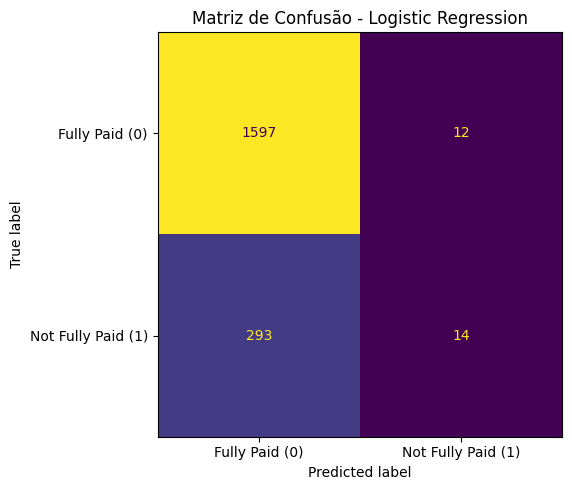

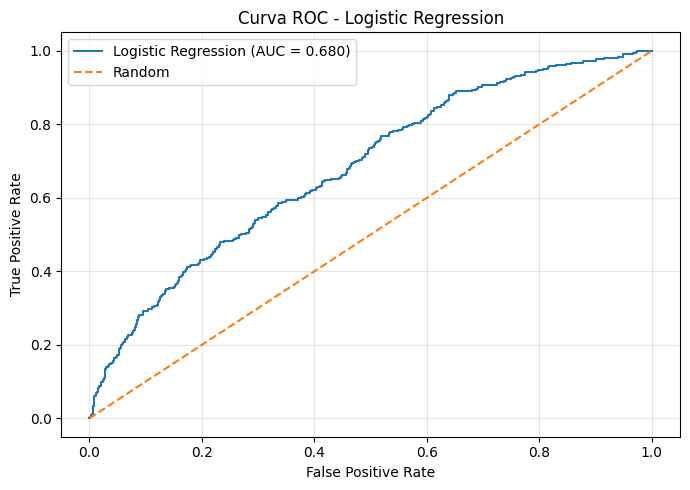

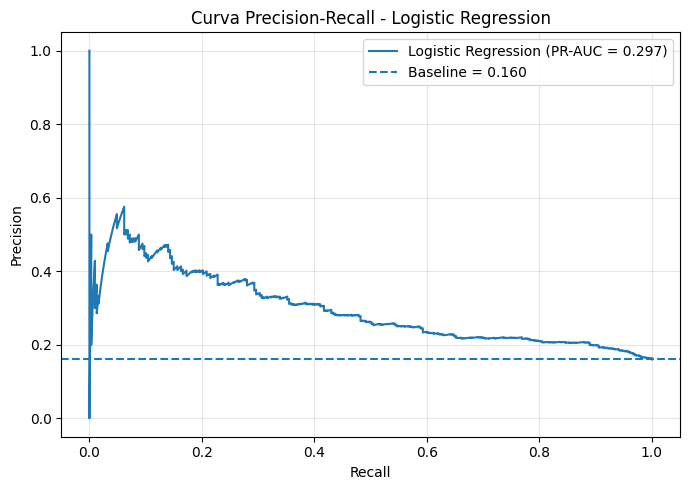

In [126]:
resultado_logis = avaliar_modelo(
    model_13,
    X_scaled_13_test,
    y_test,
    yhat_13,
    'Logistic Regression'
)

In [127]:
# logreg_result_cv = cross_validation(X_scaled_13_test, y_test, 'Logistic Regression', model_13, n_splits=5)
# logreg_result_cv

## Decision Tree Classifier

In [128]:
X_train_tree = df_train.drop('not.fully.paid', axis=1)
y_train_tree = y_train.copy()

X_test_tree = df_test.drop('not.fully.paid', axis=1)
y_test_tree = y_test.copy()


In [129]:
print(X_train_tree.shape)
print(y_train_tree.shape)

print(X_test_tree.shape)
print(y_test_tree.shape)

(7662, 13)
(7662,)
(1916, 13)
(1916,)


In [130]:
X_train_enco = df_train.drop('not.fully.paid', axis=1)
X_test_enco = df_test.drop('not.fully.paid', axis=1)

In [131]:
# id_item - One Hot Encoding
X_train_enco = pd.get_dummies( X_train_enco, prefix=['purpose'], columns=['purpose'], dtype=int )
X_test_enco = pd.get_dummies( X_test_enco, prefix=['purpose'], columns=['purpose'], dtype=int )

In [132]:
X_train_enco.shape

(7662, 19)

In [133]:
model_dt = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=20,
    class_weight='balanced',
    random_state=42
)

model_dt.fit(X_train_tree, y_train_tree)

yhat_dt = model_dt.predict(X_test_tree)
yprob_dt = model_dt.predict_proba(X_test_tree)[:, 1]

AVALIAÇÃO: Decision Tree


,Métrica,Valor
0,Accuracy,0.6018
1,Precision,0.2185
2,Recall,0.5765
3,F1-Score,0.3169
4,Specificity,0.6066
5,ROC-AUC,0.6244
6,PR-AUC,0.2209


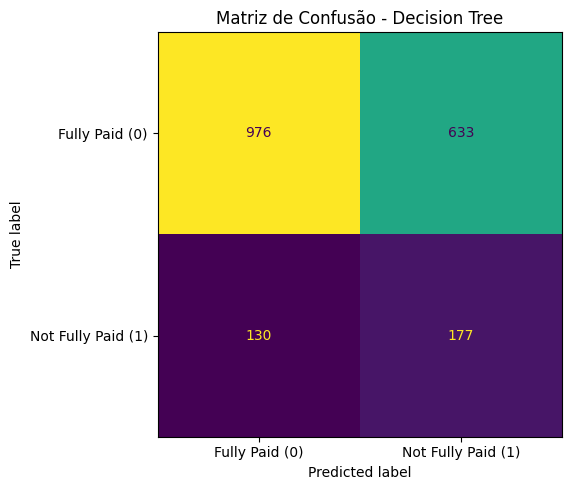

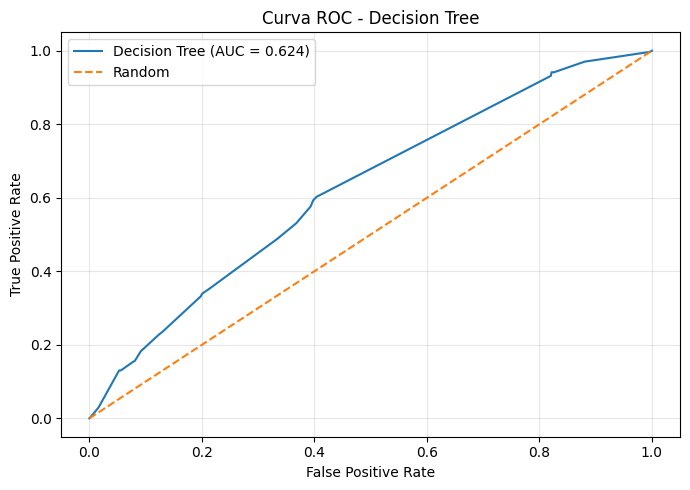

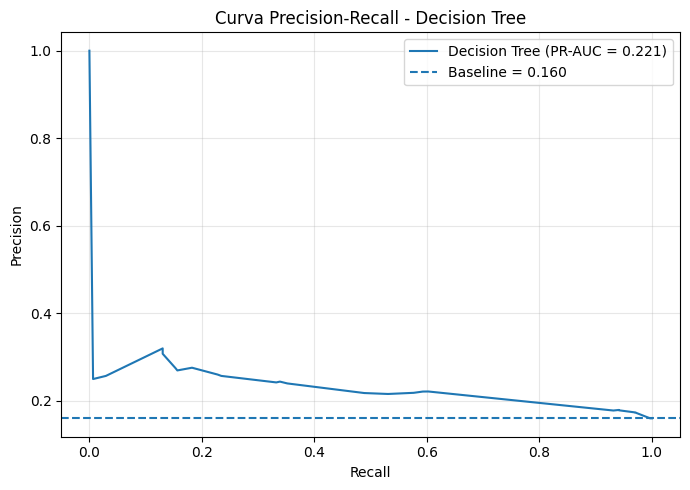

In [134]:
resultado_dt = avaliar_modelo(
    model_dt,
    X_test_tree,
    y_test_tree,
    yhat_dt,
    'Decision Tree'
)

In [135]:
model_dt_enco = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=20,
    class_weight='balanced',
    random_state=42
)

model_dt_enco.fit(X_train_enco, y_train_tree)

yhat_dt_enco = model_dt_enco.predict(X_test_enco)
yprob_dt_enco = model_dt_enco.predict_proba(X_test_enco)[:, 1]

AVALIAÇÃO: Decision Tree Encoding


,Métrica,Valor
0,Accuracy,0.6164
1,Precision,0.2263
2,Recall,0.5765
3,F1-Score,0.3251
4,Specificity,0.6240
5,ROC-AUC,0.6335
6,PR-AUC,0.2320


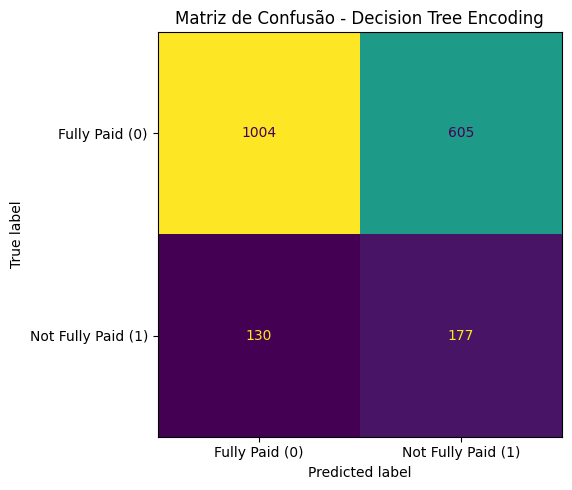

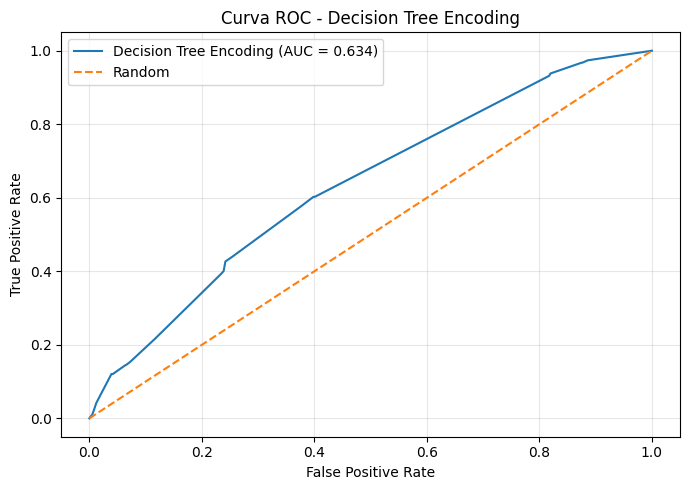

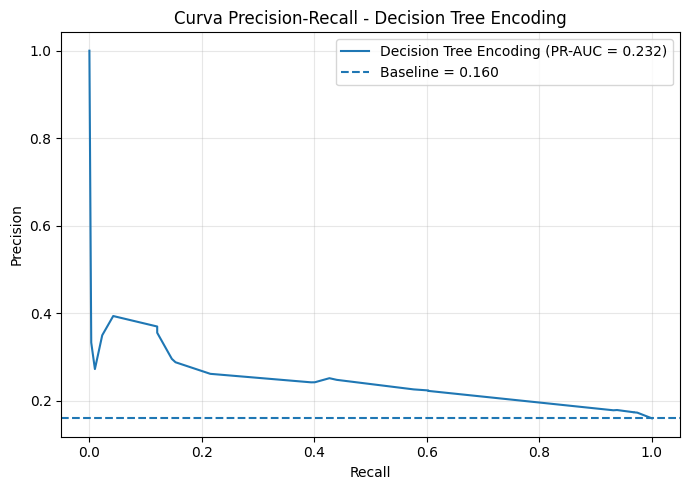

In [136]:
resultado_dt_enco = avaliar_modelo(
    model_dt_enco,
    X_test_enco,
    y_test_tree,
    yhat_dt_enco,
    'Decision Tree Encoding'
)

In [137]:
dt_result_cv_woe = cross_validation(X_train_tree, y_train_tree, 'Decision Tree CV WoE', model_dt, n_splits=5)
dt_result_cv_woe

,Modelo,Fold,Accuracy,Precision,Recall,F1-Score,Specificity,ROC-AUC,PR-AUC,TN,FP,FN,TP
0,Decision Tree CV WoE,1,0.711676,0.273563,0.485714,0.350000,0.754658,0.654926,0.250728,972,316,126,119
1,Decision Tree CV WoE,2,0.665362,0.235644,0.483740,0.316911,0.700078,0.628055,0.226792,901,386,127,119
2,Decision Tree CV WoE,3,0.601175,0.207668,0.530612,0.298507,0.614608,0.629792,0.237246,791,496,115,130
3,Decision Tree CV WoE,4,0.611619,0.227414,0.595918,0.329200,0.614608,0.644421,0.250419,791,496,99,146
4,Decision Tree CV WoE,5,0.706919,0.247525,0.408163,0.308166,0.763792,0.615615,0.212923,983,304,145,100


In [138]:
dt_result_cv = cross_validation(X_train_enco, y_train_tree, 'Decision Tree CV', model_dt_enco, n_splits=5)
dt_result_cv


,Modelo,Fold,Accuracy,Precision,Recall,F1-Score,Specificity,ROC-AUC,PR-AUC,TN,FP,FN,TP
0,Decision Tree CV,1,0.628832,0.230897,0.567347,0.328217,0.640528,0.645730,0.247160,825,463,106,139
1,Decision Tree CV,2,0.617091,0.220033,0.544715,0.313450,0.630925,0.619958,0.210365,812,475,112,134
2,Decision Tree CV,3,0.610966,0.212766,0.530612,0.303738,0.626263,0.632149,0.239191,806,481,115,130
3,Decision Tree CV,4,0.628590,0.236156,0.591837,0.337602,0.635587,0.643899,0.249666,818,469,100,145
4,Decision Tree CV,5,0.686684,0.248394,0.473469,0.325843,0.727273,0.634949,0.227478,936,351,129,116


In [139]:
resumo_cv(dt_result_cv)

{'Modelo': 'Decision Tree CV',
 'Accuracy_mean': np.float64(0.6344326471244459),
 'Accuracy_std': np.float64(0.03019575854881541),
 'Precision_mean': np.float64(0.22964923284205357),
 'Precision_std': np.float64(0.013899514259541638),
 'Recall_mean': np.float64(0.5415961506553841),
 'Recall_std': np.float64(0.044606197419599126),
 'F1-Score_mean': np.float64(0.3217700813445993),
 'F1-Score_std': np.float64(0.013258588727448225),
 'Specificity_mean': np.float64(0.6521149140714358),
 'Specificity_std': np.float64(0.04234828062878849),
 'ROC-AUC_mean': np.float64(0.6353369868333509),
 'ROC-AUC_std': np.float64(0.010345781533752986),
 'PR-AUC_mean': np.float64(0.23477184186739267),
 'PR-AUC_std': np.float64(0.01615348971167254)}

## Random Forest Classifier

In [140]:
model_rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

model_rf.fit(X_train_tree, y_train_tree)

yhat_rf = model_rf.predict(X_test_tree)
yprob_rf = model_rf.predict_proba(X_test_tree)[:, 1]

AVALIAÇÃO: Random Forest


,Métrica,Valor
0,Accuracy,0.7218
1,Precision,0.2749
2,Recall,0.4495
3,F1-Score,0.3412
4,Specificity,0.7738
5,ROC-AUC,0.6671
6,PR-AUC,0.2829


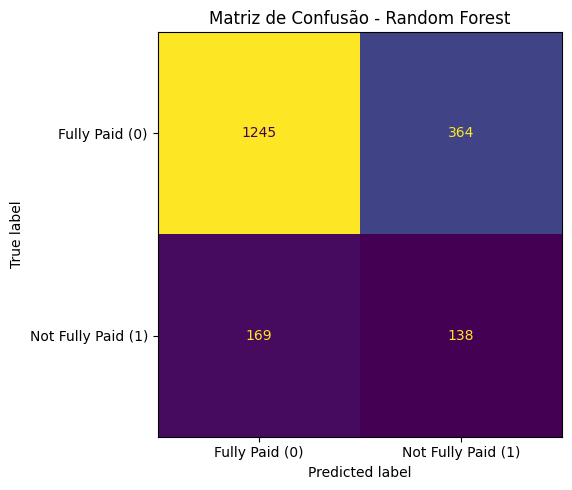

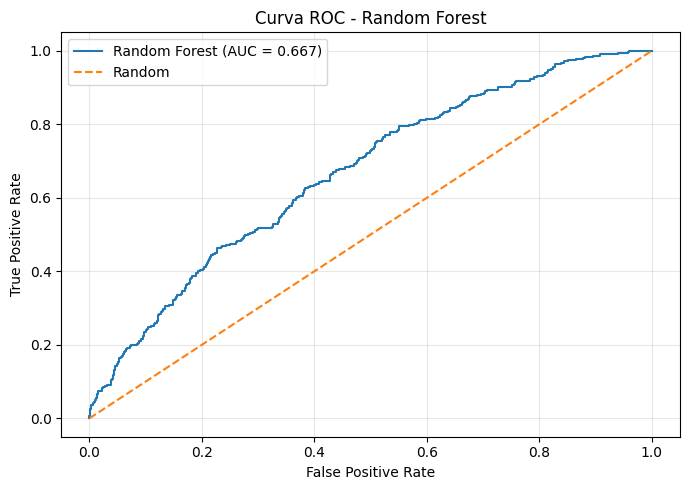

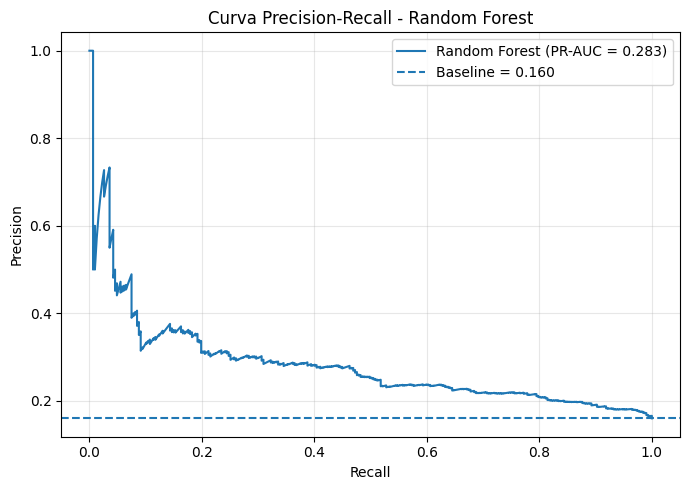

In [141]:
resultado_rf = avaliar_modelo(
    model_rf,
    X_test_tree,
    y_test_tree,
    yhat_rf,
    'Random Forest'
)

In [142]:
model_rf_enco = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

model_rf_enco.fit(X_train_enco, y_train_tree)

yhat_dt_enco = model_rf_enco.predict(X_test_enco)
yprob_dt_enco = model_rf_enco.predict_proba(X_test_enco)[:, 1]

AVALIAÇÃO: Random Forest Encoding


,Métrica,Valor
0,Accuracy,0.7150
1,Precision,0.2732
2,Recall,0.4691
3,F1-Score,0.3453
4,Specificity,0.7620
5,ROC-AUC,0.6645
6,PR-AUC,0.2756


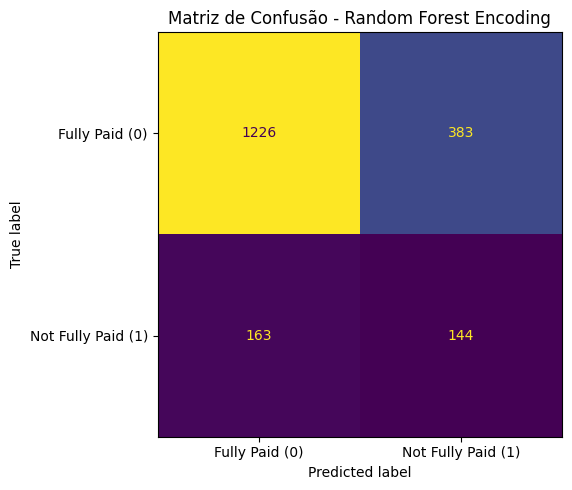

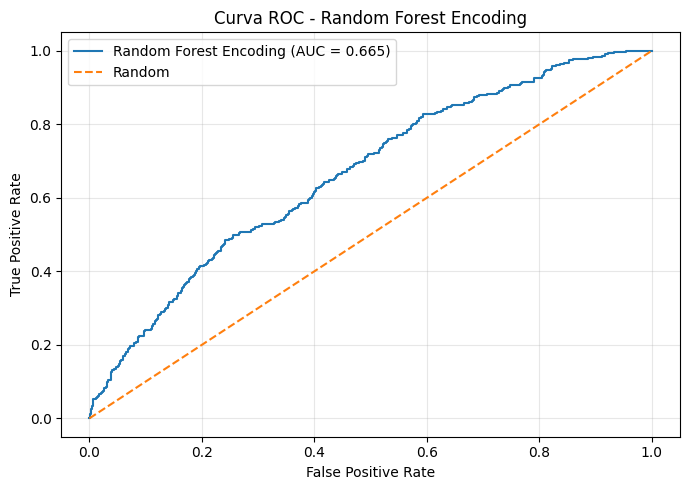

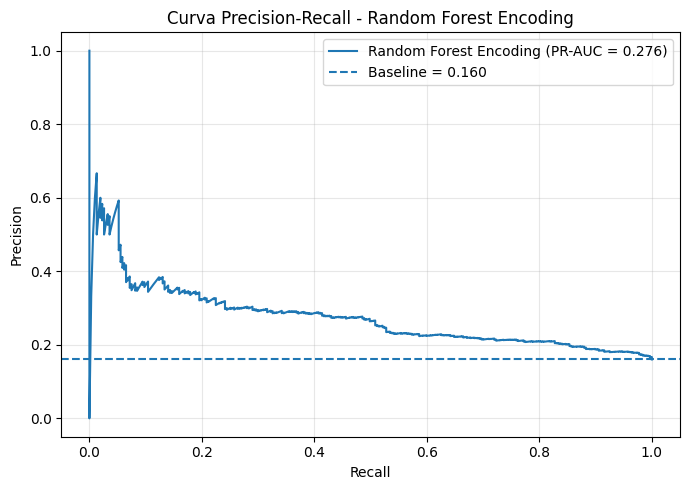

In [143]:
resultado_rf_enco = avaliar_modelo(
    model_rf_enco,
    X_test_enco,
    y_test_tree,
    yhat_dt_enco,
    'Random Forest Encoding'
)

In [144]:
rf_result_cv = cross_validation(X_train_enco, y_train_tree, 'Random Forest CV', model_rf_enco, n_splits=5)
rf_result_cv

,Modelo,Fold,Accuracy,Precision,Recall,F1-Score,Specificity,ROC-AUC,PR-AUC,TN,FP,FN,TP
0,Random Forest CV,1,0.698630,0.250575,0.444898,0.320588,0.746894,0.672785,0.281533,962,326,136,109
1,Random Forest CV,2,0.716895,0.255208,0.398374,0.311111,0.777778,0.662510,0.250283,1001,286,148,98
2,Random Forest CV,3,0.713446,0.264563,0.444898,0.331811,0.764569,0.663908,0.304730,984,303,136,109
3,Random Forest CV,4,0.718016,0.282051,0.493878,0.359050,0.760684,0.676590,0.306783,979,308,124,121
4,Random Forest CV,5,0.727154,0.270557,0.416327,0.327974,0.786325,0.665791,0.268995,1012,275,143,102


In [145]:
resumo_cv(rf_result_cv)

{'Modelo': 'Random Forest CV',
 'Accuracy_mean': np.float64(0.7148282604289615),
 'Accuracy_std': np.float64(0.010375986929974134),
 'Precision_mean': np.float64(0.26459089280042575),
 'Precision_std': np.float64(0.012499464753198884),
 'Recall_mean': np.float64(0.43967479674796744),
 'Recall_std': np.float64(0.0362056629170603),
 'F1-Score_mean': np.float64(0.330107066270906),
 'F1-Score_std': np.float64(0.018004351651276965),
 'Specificity_mean': np.float64(0.7672498998585955),
 'Specificity_std': np.float64(0.015324295637948319),
 'ROC-AUC_mean': np.float64(0.6683167735726873),
 'ROC-AUC_std': np.float64(0.00608171778222251),
 'PR-AUC_mean': np.float64(0.2824647447443683),
 'PR-AUC_std': np.float64(0.02400584167586863)}

## XGBoost Classifier

In [146]:
model_xgb = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42
)

model_xgb.fit(X_train_tree, y_train_tree)

yhat_xgb = model_xgb.predict(X_test_tree)
yprob_xgb = model_xgb.predict_proba(X_test_tree)[:, 1]

AVALIAÇÃO: XGBoost


,Métrica,Valor
0,Accuracy,0.8361
1,Precision,0.3478
2,Recall,0.0261
3,F1-Score,0.0485
4,Specificity,0.9907
5,ROC-AUC,0.6626
6,PR-AUC,0.2703


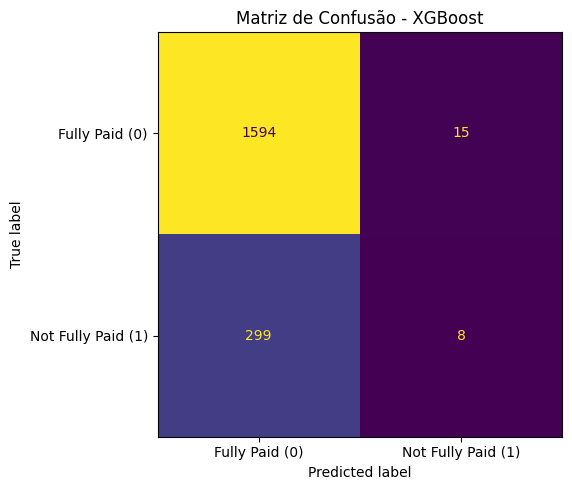

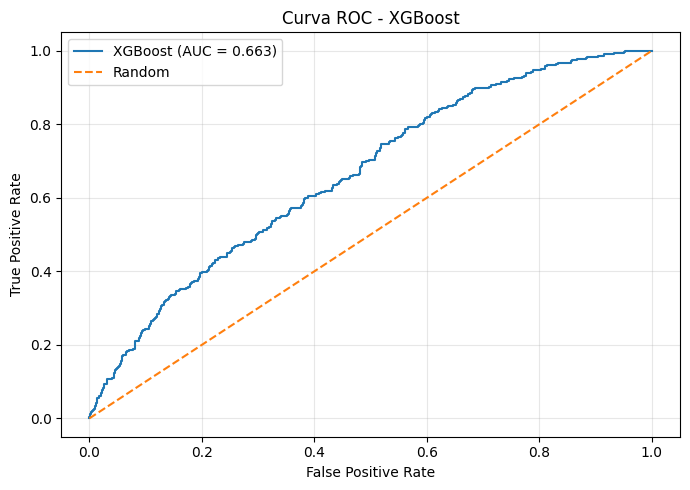

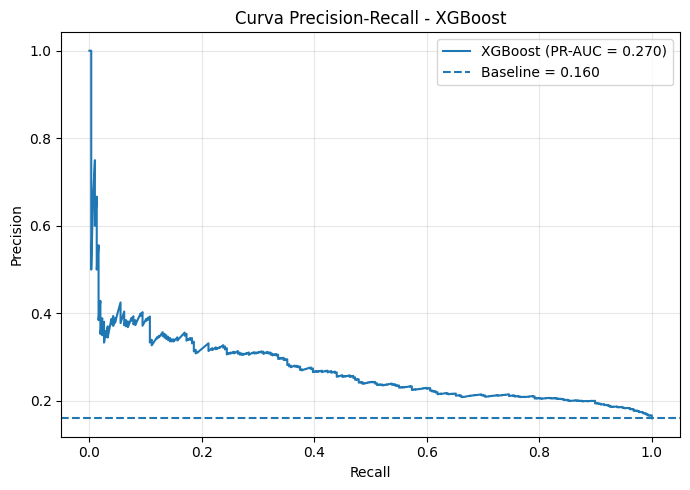

In [147]:
resultado_xgb = avaliar_modelo(
    model_xgb,
    X_test_tree,
    y_test_tree,
    yhat_xgb,
    'XGBoost'
)

In [148]:
model_xgb_enco = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42
)

model_xgb_enco.fit(X_train_enco, y_train_tree)

yhat_xgb_enco = model_xgb_enco.predict(X_test_enco)
yprob_xgb_enco = model_xgb_enco.predict_proba(X_test_enco)[:, 1]

AVALIAÇÃO: XGBoost Encoding


,Métrica,Valor
0,Accuracy,0.8387
1,Precision,0.4583
2,Recall,0.0358
3,F1-Score,0.0665
4,Specificity,0.9919
5,ROC-AUC,0.6698
6,PR-AUC,0.2718


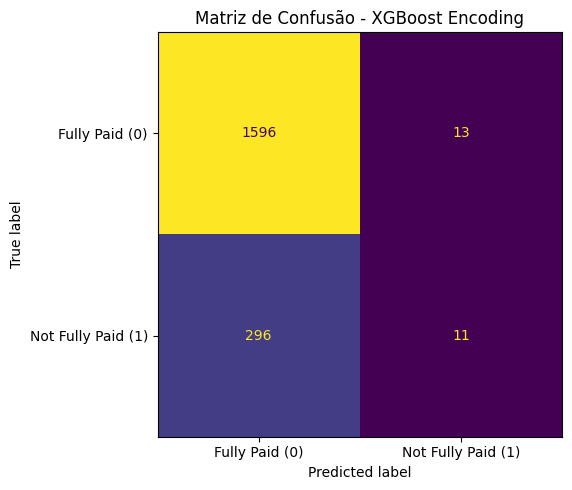

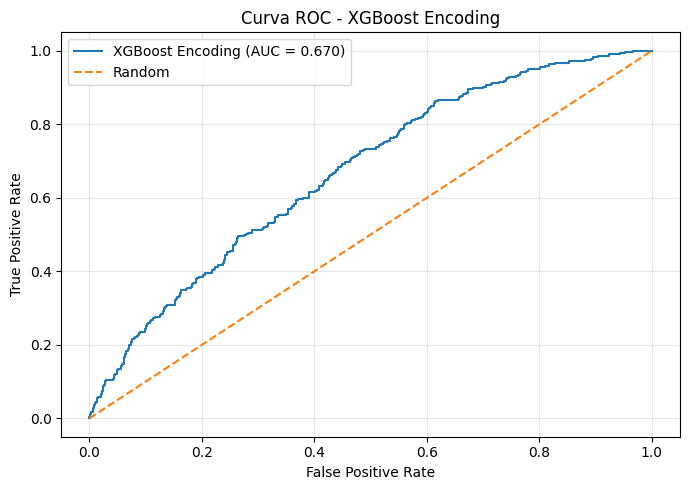

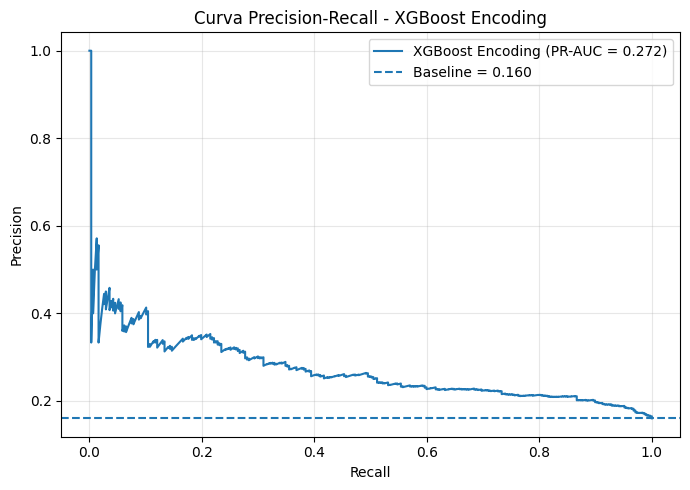

In [149]:
resultado_xgb_enco = avaliar_modelo(
    model_xgb_enco,
    X_test_enco,
    y_test_tree,
    yhat_xgb_enco,
    'XGBoost Encoding'
)

In [150]:
xgb_result_cv = cross_validation(X_train_enco, y_train_tree, 'XGBoost CV', model_xgb_enco, n_splits=5)
xgb_result_cv

,Modelo,Fold,Accuracy,Precision,Recall,F1-Score,Specificity,ROC-AUC,PR-AUC,TN,FP,FN,TP
0,XGBoost CV,1,0.837573,0.333333,0.016327,0.031128,0.993789,0.683357,0.281174,1280,8,241,4
1,XGBoost CV,2,0.834964,0.266667,0.016260,0.030651,0.991453,0.649538,0.251962,1276,11,242,4
2,XGBoost CV,3,0.839426,0.473684,0.036735,0.068182,0.992230,0.664158,0.280691,1277,10,236,9
3,XGBoost CV,4,0.842689,0.625000,0.040816,0.076628,0.995338,0.673184,0.319601,1281,6,235,10
4,XGBoost CV,5,0.842037,0.565217,0.053061,0.097015,0.992230,0.666711,0.289814,1277,10,232,13


In [151]:
resumo_cv(xgb_result_cv)

{'Modelo': 'XGBoost CV',
 'Accuracy_mean': np.float64(0.8393377888370555),
 'Accuracy_std': np.float64(0.003192401461917032),
 'Precision_mean': np.float64(0.45278032036613275),
 'Precision_std': np.float64(0.1513642629575791),
 'Recall_mean': np.float64(0.032639787622366016),
 'Recall_std': np.float64(0.016086279865039962),
 'F1-Score_mean': np.float64(0.06072096834216064),
 'F1-Score_std': np.float64(0.029179885114569475),
 'Specificity_mean': np.float64(0.9930079582253496),
 'Specificity_std': np.float64(0.0015546061966312111),
 'ROC-AUC_mean': np.float64(0.6673895135690968),
 'ROC-AUC_std': np.float64(0.012430859051117588),
 'PR-AUC_mean': np.float64(0.2846486245655929),
 'PR-AUC_std': np.float64(0.024210052195898602)}

In [152]:
resultados = pd.DataFrame([
    resultado_logis,
    resultado_dt,
    resultado_dt_enco,
    resultado_rf,
    resultado_rf_enco,
    resultado_xgb,
    resultado_xgb_enco
])

resultados.sort_values(
    'PR-AUC',
    ascending=False
)

,Modelo,Accuracy,Precision,Recall,F1-Score,Specificity,ROC-AUC,PR-AUC,TN,FP,FN,TP
0,Logistic Regression,0.840814,0.538462,0.045603,0.084084,0.992542,0.680021,0.296622,1597,12,293,14
3,Random Forest,0.721816,0.274900,0.449511,0.341162,0.773773,0.667103,0.282929,1245,364,169,138
4,Random Forest Encoding,0.715031,0.273245,0.469055,0.345324,0.761964,0.664538,0.275566,1226,383,163,144
6,XGBoost Encoding,0.838727,0.458333,0.035831,0.066465,0.991920,0.669781,0.271827,1596,13,296,11
5,XGBoost,0.836117,0.347826,0.026059,0.048485,0.990677,0.662570,0.270288,1594,15,299,8
2,Decision Tree Encoding,0.616388,0.226343,0.576547,0.325069,0.623990,0.633512,0.231989,1004,605,130,177
1,Decision Tree,0.601775,0.218519,0.576547,0.316920,0.606588,0.624364,0.220909,976,633,130,177


In [153]:
resultados_cv = pd.DataFrame([
    resumo_cv(dt_result_cv),
    resumo_cv(rf_result_cv),
    resumo_cv(xgb_result_cv)
])

In [154]:
resultados_cv = resultados_cv.sort_values(
    'PR-AUC_mean',
    ascending=False
).reset_index(drop=True)

resultados_cv

,Modelo,Accuracy_mean,Accuracy_std,Precision_mean,Precision_std,Recall_mean,Recall_std,F1-Score_mean,F1-Score_std,Specificity_mean,Specificity_std,ROC-AUC_mean,ROC-AUC_std,PR-AUC_mean,PR-AUC_std
0,XGBoost CV,0.839338,0.003192,0.452780,0.151364,0.032640,0.016086,0.060721,0.029180,0.993008,0.001555,0.667390,0.012431,0.284649,0.024210
1,Random Forest CV,0.714828,0.010376,0.264591,0.012499,0.439675,0.036206,0.330107,0.018004,0.767250,0.015324,0.668317,0.006082,0.282465,0.024006
2,Decision Tree CV,0.634433,0.030196,0.229649,0.013900,0.541596,0.044606,0.321770,0.013259,0.652115,0.042348,0.635337,0.010346,0.234772,0.016153


In [155]:
lr_result_cv = cross_validation(X_train_enco, y_train_tree, 'Logistic Regression CV', model_13, n_splits=5)
lr_result_cv

/home/deivisson/.pyenv/versions/3.13.1/envs/rossmann/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/deivisson/.pyenv/versions/3.13.1/envs/rossmann/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown

,Modelo,Fold,Accuracy,Precision,Recall,F1-Score,Specificity,ROC-AUC,PR-AUC,TN,FP,FN,TP
0,Logistic Regression CV,1,0.839530,0.428571,0.012245,0.023810,0.996894,0.668586,0.273117,1284,4,242,3
1,Logistic Regression CV,2,0.838226,0.333333,0.008130,0.015873,0.996892,0.663988,0.271695,1283,4,244,2
2,Logistic Regression CV,3,0.838120,0.384615,0.020408,0.038760,0.993784,0.655595,0.278700,1279,8,240,5
3,Logistic Regression CV,4,0.842037,0.636364,0.028571,0.054688,0.996892,0.667352,0.317061,1283,4,238,7
4,Logistic Regression CV,5,0.838120,0.421053,0.032653,0.060606,0.991453,0.666543,0.272877,1276,11,237,8


In [156]:
resumo_cv(lr_result_cv)

{'Modelo': 'Logistic Regression CV',
 'Accuracy_mean': np.float64(0.8392065592645013),
 'Accuracy_std': np.float64(0.0016908982362387128),
 'Precision_mean': np.float64(0.440787282892546),
 'Precision_std': np.float64(0.1156399877078065),
 'Recall_mean': np.float64(0.020401526464244236),
 'Recall_std': np.float64(0.010415930148554603),
 'F1-Score_mean': np.float64(0.03874715804221618),
 'F1-Score_std': np.float64(0.01922410970969294),
 'Specificity_mean': np.float64(0.9951830777917735),
 'Specificity_std': np.float64(0.002481957234328177),
 'ROC-AUC_mean': np.float64(0.66441282119978),
 'ROC-AUC_std': np.float64(0.0052086655567752434),
 'PR-AUC_mean': np.float64(0.28269000274424266),
 'PR-AUC_std': np.float64(0.01940454611249495)}

In [157]:
resultados_cv = pd.DataFrame([
    resumo_cv(dt_result_cv),
    resumo_cv(rf_result_cv),
    resumo_cv(xgb_result_cv),
    resumo_cv(lr_result_cv)
])

In [158]:
resultados_cv = resultados_cv.sort_values(
    'PR-AUC_mean',
    ascending=False
).reset_index(drop=True)

resultados_cv

,Modelo,Accuracy_mean,Accuracy_std,Precision_mean,Precision_std,Recall_mean,Recall_std,F1-Score_mean,F1-Score_std,Specificity_mean,Specificity_std,ROC-AUC_mean,ROC-AUC_std,PR-AUC_mean,PR-AUC_std
0,XGBoost CV,0.839338,0.003192,0.452780,0.151364,0.032640,0.016086,0.060721,0.029180,0.993008,0.001555,0.667390,0.012431,0.284649,0.024210
1,Logistic Regression CV,0.839207,0.001691,0.440787,0.115640,0.020402,0.010416,0.038747,0.019224,0.995183,0.002482,0.664413,0.005209,0.282690,0.019405
2,Random Forest CV,0.714828,0.010376,0.264591,0.012499,0.439675,0.036206,0.330107,0.018004,0.767250,0.015324,0.668317,0.006082,0.282465,0.024006
3,Decision Tree CV,0.634433,0.030196,0.229649,0.013900,0.541596,0.044606,0.321770,0.013259,0.652115,0.042348,0.635337,0.010346,0.234772,0.016153


In [159]:
model_logis_scaled = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000))
])

In [160]:
logis_scaled_result_cv = cross_validation(
    X_train_enco,
    y_train_tree,
    'Logistic Regression OHE + Scaling',
    model_logis_scaled,
    n_splits=5
)

logis_scaled_result_cv

,Modelo,Fold,Accuracy,Precision,Recall,F1-Score,Specificity,ROC-AUC,PR-AUC,TN,FP,FN,TP
0,Logistic Regression OHE + Scaling,1,0.837573,0.333333,0.016327,0.031128,0.993789,0.679354,0.286081,1280,8,241,4
1,Logistic Regression OHE + Scaling,2,0.838878,0.454545,0.020325,0.038911,0.995338,0.681228,0.278923,1281,6,241,5
2,Logistic Regression OHE + Scaling,3,0.840731,0.538462,0.028571,0.054264,0.995338,0.670028,0.283647,1281,6,238,7
3,Logistic Regression OHE + Scaling,4,0.842037,0.636364,0.028571,0.054688,0.996892,0.682394,0.327760,1283,4,238,7
4,Logistic Regression OHE + Scaling,5,0.838773,0.444444,0.032653,0.060837,0.992230,0.672895,0.281847,1277,10,237,8


In [161]:
resumo_cv(logis_scaled_result_cv)

{'Modelo': 'Logistic Regression OHE + Scaling',
 'Accuracy_mean': np.float64(0.839598374490538),
 'Accuracy_std': np.float64(0.001769795886423685),
 'Precision_mean': np.float64(0.48142968142968134),
 'Precision_std': np.float64(0.1132258371987931),
 'Recall_mean': np.float64(0.02528953044632487),
 'Recall_std': np.float64(0.006722038504906988),
 'F1-Score_mean': np.float64(0.04796529565969003),
 'F1-Score_std': np.float64(0.012409616293219688),
 'Specificity_mean': np.float64(0.9947173599347513),
 'Specificity_std': np.float64(0.0017712006692592814),
 'ROC-AUC_mean': np.float64(0.6771798477030369),
 'ROC-AUC_std': np.float64(0.005426715450606167),
 'PR-AUC_mean': np.float64(0.29165174867020366),
 'PR-AUC_std': np.float64(0.020353224532606743)}

In [162]:
resultados_cv = pd.DataFrame([
    resumo_cv(dt_result_cv),
    resumo_cv(rf_result_cv),
    resumo_cv(xgb_result_cv),
    resumo_cv(lr_result_cv),
    resumo_cv(logis_scaled_result_cv)
])

resultados_cv

,Modelo,Accuracy_mean,Accuracy_std,Precision_mean,Precision_std,Recall_mean,Recall_std,F1-Score_mean,F1-Score_std,Specificity_mean,Specificity_std,ROC-AUC_mean,ROC-AUC_std,PR-AUC_mean,PR-AUC_std
0,Decision Tree CV,0.634433,0.030196,0.229649,0.013900,0.541596,0.044606,0.321770,0.013259,0.652115,0.042348,0.635337,0.010346,0.234772,0.016153
1,Random Forest CV,0.714828,0.010376,0.264591,0.012499,0.439675,0.036206,0.330107,0.018004,0.767250,0.015324,0.668317,0.006082,0.282465,0.024006
2,XGBoost CV,0.839338,0.003192,0.452780,0.151364,0.032640,0.016086,0.060721,0.029180,0.993008,0.001555,0.667390,0.012431,0.284649,0.024210
3,Logistic Regression CV,0.839207,0.001691,0.440787,0.115640,0.020402,0.010416,0.038747,0.019224,0.995183,0.002482,0.664413,0.005209,0.282690,0.019405
4,Logistic Regression OHE + Scaling,0.839598,0.001770,0.481430,0.113226,0.025290,0.006722,0.047965,0.012410,0.994717,0.001771,0.677180,0.005427,0.291652,0.020353


In [163]:
thresholds = np.arange(
    0.10,
    0.51,
    0.05
)

In [164]:
logis_threshold_cv = cross_validation_threshold(
    X_train_enco,
    y_train_tree,
    'Logistic Regression',
    model_logis_scaled,
    thresholds=thresholds,
    n_splits=5
)

logis_threshold_cv

,Modelo,Fold,Threshold,Accuracy,Precision,Recall,F1-Score,Specificity,TN,FP,FN,TP
0,Logistic Regression,1,0.10,0.388780,0.192171,0.881633,0.315559,0.295031,380,908,29,216
1,Logistic Regression,1,0.15,0.600783,0.234443,0.661224,0.346154,0.589286,759,529,83,162
2,Logistic Regression,1,0.20,0.727332,0.279898,0.448980,0.344828,0.780280,1005,283,135,110
3,Logistic Regression,1,0.25,0.787997,0.331933,0.322449,0.327122,0.876553,1129,159,166,79
4,Logistic Regression,1,0.30,0.819309,0.382353,0.212245,0.272966,0.934783,1204,84,193,52
5,Logistic Regression,1,0.35,0.831050,0.400000,0.114286,0.177778,0.967391,1246,42,217,28
6,Logistic Regression,1,0.40,0.837573,0.444444,0.065306,0.113879,0.984472,1268,20,229,16
7,Logistic Regression,1,0.45,0.838226,0.428571,0.036735,0.067669,0.990683,1276,12,236,9
8,Logistic Regression,1,0.50,0.837573,0.333333,0.016327,0.031128,0.993789,1280,8,241,4
9,Logistic Regression,2,0.10,0.383562,0.196351,0.918699,0.323550,0.281274,362,925,20,226


In [165]:
rf_threshold_cv = cross_validation_threshold(
    X_train_enco,
    y_train_tree,
    'Random Forest',
    model_rf_enco,
    thresholds=thresholds,
    n_splits=5
)

rf_threshold_cv

,Modelo,Fold,Threshold,Accuracy,Precision,Recall,F1-Score,Specificity,TN,FP,FN,TP
0,Random Forest,1,0.10,0.177430,0.162683,1.000000,0.279840,0.020963,27,1261,0,245
1,Random Forest,1,0.15,0.209393,0.167698,0.995918,0.287059,0.059783,77,1211,1,244
2,Random Forest,1,0.20,0.254403,0.175578,0.991837,0.298343,0.114130,147,1141,2,243
3,Random Forest,1,0.25,0.281800,0.179160,0.975510,0.302723,0.149845,193,1095,6,239
4,Random Forest,1,0.30,0.325506,0.186158,0.955102,0.311585,0.205745,265,1023,11,234
5,Random Forest,1,0.35,0.382909,0.194952,0.914286,0.321377,0.281832,363,925,21,224
6,Random Forest,1,0.40,0.459230,0.202648,0.812245,0.324368,0.392081,505,783,46,199
7,Random Forest,1,0.45,0.588389,0.230447,0.673469,0.343392,0.572205,737,551,80,165
8,Random Forest,1,0.50,0.698630,0.250575,0.444898,0.320588,0.746894,962,326,136,109
9,Random Forest,2,0.10,0.180691,0.163782,1.000000,0.281465,0.024087,31,1256,0,246


In [166]:
xgb_threshold_cv = cross_validation_threshold(
    X_train_enco,
    y_train_tree,
    'XGBoost',
    model_xgb_enco,
    thresholds=thresholds,
    n_splits=5
)

xgb_threshold_cv

,Modelo,Fold,Threshold,Accuracy,Precision,Recall,F1-Score,Specificity,TN,FP,FN,TP
0,XGBoost,1,0.10,0.420091,0.200743,0.881633,0.327025,0.332298,428,860,29,216
1,XGBoost,1,0.15,0.613177,0.241071,0.661224,0.353326,0.604037,778,510,83,162
2,XGBoost,1,0.20,0.724070,0.285024,0.481633,0.358118,0.770186,992,296,127,118
3,XGBoost,1,0.25,0.774951,0.298387,0.302041,0.300203,0.864907,1114,174,171,74
4,XGBoost,1,0.30,0.801044,0.294521,0.175510,0.219949,0.920031,1185,103,202,43
5,XGBoost,1,0.35,0.822570,0.354839,0.134694,0.195266,0.953416,1228,60,212,33
6,XGBoost,1,0.40,0.833659,0.403846,0.085714,0.141414,0.975932,1257,31,224,21
7,XGBoost,1,0.45,0.835616,0.393939,0.053061,0.093525,0.984472,1268,20,232,13
8,XGBoost,1,0.50,0.837573,0.333333,0.016327,0.031128,0.993789,1280,8,241,4
9,XGBoost,2,0.10,0.405088,0.190520,0.833333,0.310136,0.323232,416,871,41,205


In [167]:
threshold_cv = pd.concat(
    [
        logis_threshold_cv,
        rf_threshold_cv,
        xgb_threshold_cv
    ],
    ignore_index=True
)

In [168]:
metricas = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1-Score',
    'Specificity'
]

threshold_summary = (
    threshold_cv
    .groupby(['Modelo', 'Threshold'])[metricas]
    .agg(['mean', 'std'])
    .reset_index()
)

In [169]:
threshold_summary

Modelo Threshold  Accuracy           Precision            \
                                       mean       std      mean       std   
0   Logistic Regression      0.10  0.394808  0.008612  0.193847  0.001674   
1   Logistic Regression      0.15  0.612244  0.009209  0.239348  0.005080   
2   Logistic Regression      0.20  0.732448  0.010177  0.283536  0.011874   
3   Logistic Regression      0.25  0.790657  0.008174  0.326217  0.028224   
4   Logistic Regression      0.30  0.818585  0.007113  0.368168  0.041428   
5   Logistic Regression      0.35  0.831115  0.004159  0.404182  0.042270   
6   Logistic Regression      0.40  0.837118  0.004171  0.450873  0.069485   
7   Logistic Regression      0.45  0.839076  0.002737  0.484365  0.091047   
8   Logistic Regression      0.50  0.839598  0.001770  0.481430  0.113226   
9         Random Forest      0.10  0.181154  0.007802  0.163204  0.001044   
10        Random Forest      0.15  0.214696  0.008977  0.168266  0.000879   
11        Random Forest      0.20  0.251240  0.006752  0.173917  0.000990   
12        Random Forest      0.25  0.279693  0.006401  0.177846  0.001168   
13        Random Forest      0.30  0.311276  0.009493  0.182282  0.003157   
14        Random Forest      0.35  0.356303  0.018027  0.188631  0.005102   
15        Random Forest      0.40  0.441400  0.018127  0.198290  0.003154   
16        Random Forest      0.45  0.596973  0.009068  0.231064  0.003914   
17        Random Forest      0.50  0.714828  0.010376  0.264591  0.012499   
18              XGBoost      0.10  0.409161  0.012233  0.193745  0.004438   
19              XGBoost      0.15  0.612243  0.011265  0.233340  0.007843   
20              XGBoost      0.20  0.722397  0.006409  0.271173  0.015108   
21              XGBoost      0.25  0.775385  0.008786  0.295566  0.032389   
22              XGBoost      0.30  0.807362  0.007069  0.331344  0.038832   
23              XGBoost      0.35  0.826157  0.007259  0.383135  0.065789   
24              XGBoost      0.40  0.833987  0.004030  0.413729  0.062859   
25              XGBoost      0.45  0.837902  0.002811  0.448442  0.069374   
26              XGBoost      0.50  0.839338  0.003192  0.452780  0.151364   

      Recall            F1-Score           Specificity            
        mean       std      mean       std        mean       std  
0   0.880883  0.022197  0.317751  0.003409    0.302207  0.014250  
1   0.653317  0.021315  0.350291  0.007234    0.604415  0.013270  
2   0.438832  0.006684  0.344373  0.009148    0.788379  0.012103  
3   0.289590  0.030448  0.306619  0.028240    0.886111  0.007615  
4   0.186816  0.026252  0.247540  0.031350    0.938938  0.006735  
5   0.115852  0.022223  0.179250  0.028774    0.967371  0.006751  
6   0.070161  0.011037  0.120927  0.017162    0.983219  0.005484  
7   0.042422  0.009431  0.077522  0.015134    0.990833  0.004340  
8   0.025290  0.006722  0.047965  0.012410    0.994717  0.001771  
9   0.997551  0.003651  0.280512  0.001463    0.025638  0.009876  
10  0.991027  0.007852  0.287682  0.001069    0.066813  0.012094  
11  0.981238  0.013724  0.295461  0.001881    0.112181  0.010224  
12  0.966557  0.013662  0.300411  0.002166    0.148850  0.009586  
13  0.947802  0.017869  0.305756  0.005214    0.190022  0.011346  
14  0.915172  0.021864  0.312770  0.007801    0.249840  0.021922  
15  0.818079  0.020584  0.319160  0.003668    0.369636  0.025154  
16  0.652537  0.028345  0.341205  0.007024    0.586391  0.015134  
17  0.439675  0.036206  0.330107  0.018004    0.767250  0.015324  
18  0.851565  0.023947  0.315653  0.007099    0.324890  0.015561  
19  0.622363  0.022155  0.339372  0.010608    0.610318  0.013562  
20  0.436406  0.036540  0.334413  0.021865    0.776881  0.006440  
21  0.293645  0.041182  0.294507  0.036735    0.867154  0.004809  
22  0.201483  0.028632  0.250543  0.033149    0.922779  0.003401  
23  0.142778  0.027845  0.207726  0.038292    0.956340  0.005636  
24  0.090562  0.018891  0.148198  0.02825

In [170]:
melhores_thresholds = (
    threshold_cv
    .groupby(['Modelo', 'Threshold'])['F1-Score']
    .mean()
    .reset_index()
)

melhores_thresholds.loc[
    melhores_thresholds.groupby('Modelo')['F1-Score'].idxmax()]

,Modelo,Threshold,F1-Score
1,Logistic Regression,0.15,0.350291
16,Random Forest,0.45,0.341205
19,XGBoost,0.15,0.339372


In [171]:
candidatos = threshold_summary[
    (threshold_summary[('Recall', 'mean')] >= 0.50) &
    (threshold_summary[('Specificity', 'mean')] >= 0.80)]

In [172]:
candidatos.sort_values(
    ('F1-Score', 'mean'),
    ascending=False
)

Empty DataFrame
Columns: [(Modelo, ), (Threshold, ), (Accuracy, mean), (Accuracy, std), (Precision, mean), (Precision, std), (Recall, mean), (Recall, std), (F1-Score, mean), (F1-Score, std), (Specificity, mean), (Specificity, std)]
Index: []

## Logist Regression Hyperparameters

In [173]:
pipeline_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        max_iter=5000
    ))
])

In [174]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [175]:
param_grid_lr = {
    'model__C': [0.001, 0.01, 0.05, 0.1, 0.5, 1, 5, 10, 50, 100],
    'model__penalty': ['l1', 'l2'],
    'model__solver': ['liblinear']
}

In [176]:
# grid_lr = GridSearchCV(
#     estimator=pipeline_lr,
#     param_grid=param_grid_lr,
#     cv=cv,
#     scoring='roc_auc',
#     n_jobs=-1,
#     verbose=1,
#     return_train_score=True
# )

# grid_lr.fit(X_train_enco, y_train_tree)

# print("Melhores parâmetros:", grid_lr.best_params_)
# print("Melhor ROC AUC:", grid_lr.best_score_)

In [177]:
# random_lr = RandomizedSearchCV(
#     estimator=pipeline_lr,
#     param_distributions=param_grid_lr,
#     n_iter=15,
#     cv=cv,
#     scoring='roc_auc',
#     n_jobs=-1,
#     random_state=42,
#     verbose=1,
#     return_train_score=True
# )

# random_lr.fit(X_train_enco, y_train_tree)

# print("Melhores parâmetros:", random_lr.best_params_)
# print("Melhor ROC AUC:", random_lr.best_score_)

## Random Forest Hyperparameters

In [178]:
# rf = RandomForestClassifier(random_state=42)

# param_dist_rf = {
#     'n_estimators': [200, 500, 800],
#     'max_depth': [3, 5, 8, 12, None],
#     'min_samples_split': [2, 5, 10, 20],
#     'min_samples_leaf': [1, 2, 5, 10],
#     'max_features': ['sqrt', 'log2', None],
#     'class_weight': [None, 'balanced', 'balanced_subsample']
# }

# random_rf = RandomizedSearchCV(
#     estimator=rf,
#     param_distributions=param_dist_rf,
#     n_iter=50,
#     cv=cv,
#     scoring='roc_auc',
#     n_jobs=-1,
#     random_state=42,
#     verbose=1,
#     return_train_score=True
# )

# random_rf.fit(X_train_enco, y_train_tree)

# print("Melhores parâmetros:", random_rf.best_params_)
# print("Melhor ROC AUC:", random_rf.best_score_)

In [179]:
# comparacao = pd.DataFrame({
#     'Modelo': [
#         'Logistic Grid',
#         'Logistic Random',
#         'Random Forest Random'        
#     ],
#     'ROC AUC CV': [
#         grid_lr.best_score_,
#         random_lr.best_score_,
#         random_rf.best_score_
#     ]
# })

# comparacao.sort_values('ROC AUC CV', ascending=False)

In [180]:
best_lr = grid_lr.best_estimator_      # ou random_lr.best_estimator_
best_rf = random_rf.best_estimator_    # ou grid_rf.best_estimator_

NameError: name 'grid_lr' is not defined

In [ ]:
# Regressão Logística
y_pred_lr = best_lr.predict(X_test_enco)
y_prob_lr = best_lr.predict_proba(X_test_enco)[:, 1]

# Random Forest
y_pred_rf = best_rf.predict(X_test_enco)
y_prob_rf = best_rf.predict_proba(X_test_enco)[:, 1]

In [ ]:
comparacao = pd.DataFrame({
    'Modelo': ['Regressão Logística', 'Random Forest'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf)
    ],
    'Precision': [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf)
    ],
    'Recall': [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf)
    ],
    'F1': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf)
    ],
    'ROC AUC': [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_rf)
    ],
    'PR AUC': [
        average_precision_score(y_test, y_prob_lr),
        average_precision_score(y_test, y_prob_rf)
    ]
})

comparacao

/home/deivisson/.pyenv/versions/3.13.1/envs/rossmann/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,Modelo,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
0,Regressão Logística,0.840814,0.541667,0.042345,0.07855,0.682932,0.301426
1,Random Forest,0.839770,0.000000,0.000000,0.00000,0.673660,0.277985


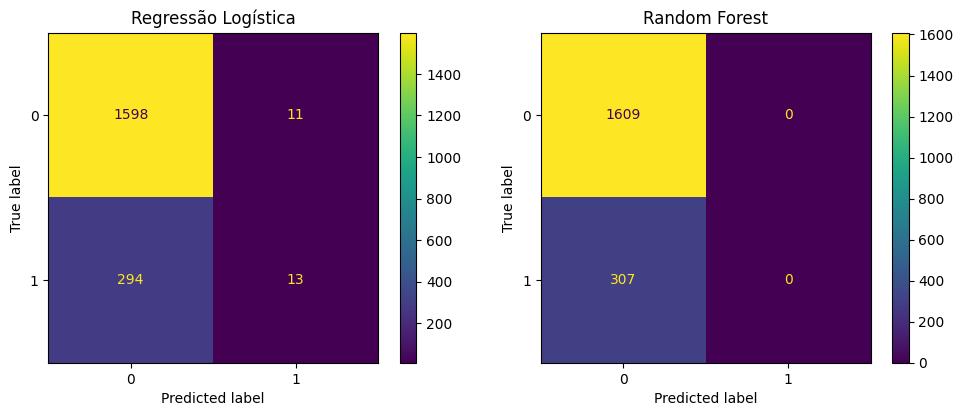

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10,4))

ConfusionMatrixDisplay.from_estimator(best_lr, X_test_enco, y_test, ax=ax[0])
ax[0].set_title("Regressão Logística")

ConfusionMatrixDisplay.from_estimator(best_rf, X_test_enco, y_test, ax=ax[1])
ax[1].set_title("Random Forest")

plt.tight_layout()

In [ ]:
y_test.mean()

np.float64(0.16022964509394572)

In [181]:
rf = RandomForestClassifier(random_state=42)

param_dist_rf = {
    'n_estimators': [200, 500, 800],
    'max_depth': [3, 5, 8, 12, None],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 5, 10],
    'max_features': ['sqrt', 'log2', None],
    'class_weight': [ 'balanced', 'balanced_subsample']
}

random_rf = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist_rf,
    n_iter=50,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    random_state=42,
    verbose=1,
    return_train_score=True
)

random_rf.fit(X_train_enco, y_train_tree)

print("Melhores parâmetros:", random_rf.best_params_)
print("Melhor ROC AUC:", random_rf.best_score_)

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Melhores parâmetros: {'n_estimators': 500, 'min_samples_split': 20, 'min_samples_leaf': 10, 'max_features': 'log2', 'max_depth': None, 'class_weight': 'balanced_subsample'}
Melhor ROC AUC: 0.6699018612194105


In [183]:
best_rf = random_rf.best_estimator_ 

In [184]:
# Random Forest
y_pred_rf = best_rf.predict(X_test_enco)
y_prob_rf = best_rf.predict_proba(X_test_enco)[:, 1]

In [186]:
comparacao = pd.DataFrame({
    'Modelo': ['Random Forest'],
    'Accuracy': [        
        accuracy_score(y_test, y_pred_rf)
    ],
    'Precision': [
        # precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf)
    ],
    'Recall': [
        # recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf)
    ],
    'F1': [
        # f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf)
    ],
    'ROC AUC': [
        # roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_rf)
    ],
    'PR AUC': [
        # average_precision_score(y_test, y_prob_lr),
        average_precision_score(y_test, y_prob_rf)
    ]
})

comparacao

,Modelo,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
0,Random Forest,0.77714,0.302632,0.299674,0.301146,0.677484,0.277113


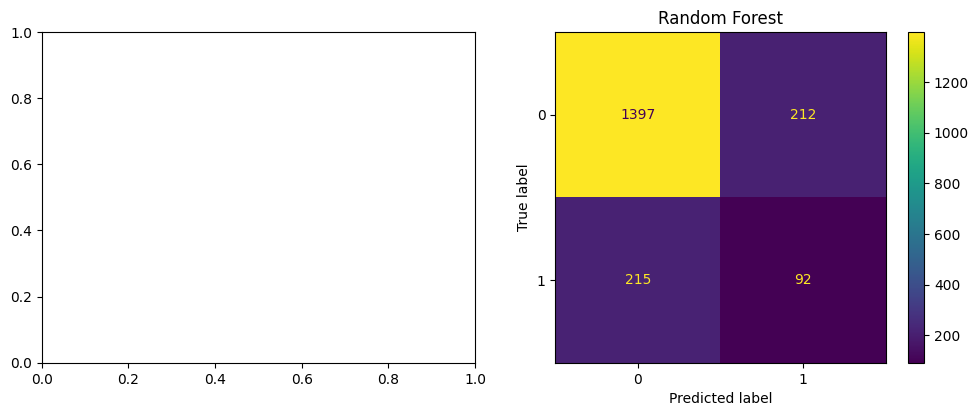

In [189]:
fig, ax = plt.subplots(1, 2, figsize=(10,4))

ConfusionMatrixDisplay.from_estimator(best_rf, X_test_enco, y_test, ax=ax[1])
ax[1].set_title("Random Forest")

plt.tight_layout()

In [204]:
precision, recall, thresholds = precision_recall_curve(y_test, y_prob_rf)

f1 = 2*(precision*recall)/(precision+recall+1e-10)

best_idx = np.argmax(f1)

print("Threshold ótimo:", thresholds[best_idx])
print("F1 máximo:", f1[best_idx])
print("Precision máximo:", precision[best_idx])
print("Recall máximo:", recall[best_idx])

Threshold ótimo: 0.32243762189740144
F1 máximo: 0.3521545319112959
Precision máximo: 0.22810394610202117
Recall máximo: 0.7719869706840391


In [203]:
y_prob_rf

array([0.48473304, 0.16423478, 0.27239794, ..., 0.31638635, 0.25158945,
       0.26421454], shape=(1916,))

In [191]:
y_pred_best = (y_prob_rf >= thresholds[best_idx]).astype(int)

In [192]:
y_pred_best

array([1, 0, 0, ..., 0, 0, 0], shape=(1916,))

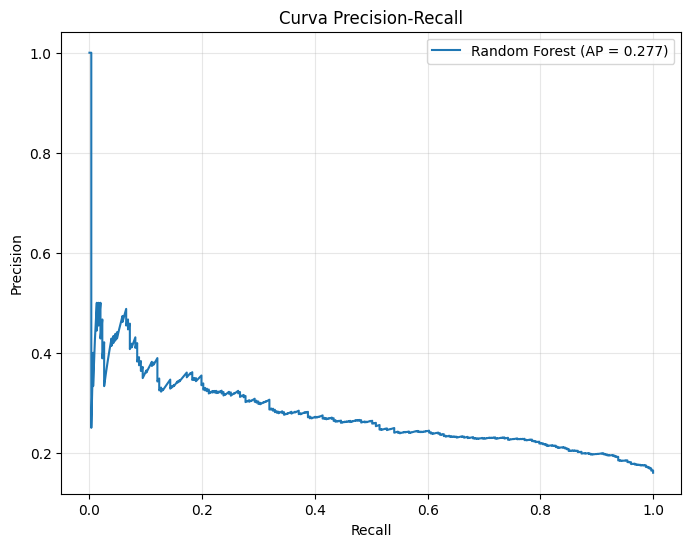

In [195]:
y_prob_rf = best_rf.predict_proba(X_test_enco)[:, 1]

precision_rf, recall_rf, thresholds_rf = precision_recall_curve(
    y_test,
    y_prob_rf
)

ap_rf = average_precision_score(y_test, y_prob_rf)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_rf,
    precision_rf,
    label=f'Random Forest (AP = {ap_rf:.3f})'
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Curva Precision-Recall')
plt.legend()
plt.grid(alpha=0.3)

plt.show()